# Conditional Diffusion Model for Return Path Distribution Estimation and Signal Classification Buy/Sell/Hold Based on Price, Volume, Market Regime, and Technical Indicator Data

## 1. Import dan Konfigurasi Eksperimen
### 1.1 Reproducibility dan konfigurasi run
### 1.2 Kontrak sumber data dan cutoff

Bagian ini menyiapkan library, seed, ticker, cutoff, context length 120 hari, horizon 60 trading days, jumlah path, epoch, output directory, dan konfigurasi GPU. Tidak ada checkpoint atau output model lama yang dibaca sebagai input training.


In [20]:
from pathlib import Path
import json, random, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn

SEED = 20260801
EPOCHS = 20
L = 120
H = 60
PATH_SAMPLES = 16
MAX_MINUTES = 30
TICKERS = ['ASII','BBCA','BBNI','BBRI','BMRI','BRIS','BRPT','IMPC','TLKM','TPIA']
OUTPUT_ROOT = Path('/kaggle/working/raw_ohlcv_full_run')
if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print('Fresh run:', True)
print('No NPZ/checkpoint/training report is loaded as input.')
print({'seed': SEED, 'epochs': EPOCHS, 'context_length': L, 'horizon': H, 'path_samples': PATH_SAMPLES})

Fresh run: True
No NPZ/checkpoint/training report is loaded as input.
{'seed': 20260801, 'epochs': 20, 'context_length': 120, 'horizon': 60, 'path_samples': 16}


### Penjelasan output

Output konfigurasi menunjukkan parameter eksperimen yang mengendalikan seluruh run: seed untuk reproducibility, context 120 hari, horizon 60 hari, jumlah path, epoch, ticker, dan device GPU. `Fresh run: True` memastikan pipeline dimulai dari raw CSV, bukan checkpoint lama. Jika angka konfigurasi berubah, hasil tidak boleh dibandingkan langsung dengan run sebelumnya.


## 2. Data Loader dan Validasi Sumber Data
### 2.1 Penemuan file CSV
### 2.2 Validasi schema OHLCV

Bagian ini mencari file CSV OHLCV Yahoo Finance yang terpasang, memvalidasi kolom date/open/high/low/close/volume, dan memastikan 10 emiten tersedia. Dataset Yahoo Finance menjadi satu-satunya sumber core eksperimen ini.


In [21]:
import pandas as pd
TICKERS = ['ASII','BBCA','BBNI','BBRI','BMRI','BRIS','BRPT','IMPC','TLKM','TPIA']
from pathlib import Path
INPUT_ROOT = Path('/kaggle/input')
LOCAL_ROOT = Path('/kaggle/working')

def normalize_columns(frame):
    frame = frame.copy()
    frame.columns = [str(c).strip().lower().replace(' ', '_') for c in frame.columns]
    aliases = {'adj_close':'adjclose', 'adj_close_':'adjclose', 'datetime':'date', 'timestamp':'date'}
    return frame.rename(columns=aliases)

def is_ohlcv(path):
    try:
        cols = set(normalize_columns(pd.read_csv(path, nrows=2)).columns)
    except Exception:
        return False
    return {'date','open','high','low','close','volume'}.issubset(cols)

all_csv = sorted(set(INPUT_ROOT.rglob('*.csv')) | set(LOCAL_ROOT.rglob('*.csv')))
raw_candidates = [p for p in all_csv if is_ohlcv(p)]
yahoo_csv = [p for p in raw_candidates if p.stem.upper() in TICKERS and ('yahoo' in str(p).lower() or 'yfinance' in str(p).lower())]
print('Total CSV:', len(all_csv))
print('OHLCV candidates:', len(raw_candidates))
print('Yahoo final:', len(yahoo_csv))
print('Yahoo tickers:', sorted(p.stem.upper() for p in yahoo_csv))
display(pd.DataFrame({'source':['Yahoo Finance raw'], 'files':[len(yahoo_csv)], 'examples':['; '.join(map(str,yahoo_csv[:10]))]}))
assert len(yahoo_csv) == 10, yahoo_csv


Total CSV: 20
OHLCV candidates: 20
Yahoo final: 10
Yahoo tickers: ['ASII', 'BBCA', 'BBNI', 'BBRI', 'BMRI', 'BRIS', 'BRPT', 'IMPC', 'TLKM', 'TPIA']


,source,files,examples
0,Yahoo Finance raw,10,/kaggle/input/datasets/rasyabramantya/idx-yaho...


### Penjelasan output

Tabel loader merangkum file yang ditemukan dan sumbernya. `Yahoo Finance raw` harus berisi 10 file, satu per emiten, dengan kolom OHLCV lengkap. Validasi ini diperlukan agar model tidak diam-diam membaca dataset yang salah, file turunan, atau file JSON/NPZ hasil training. Jika assertion gagal, perbaiki attachment atau filter sumber sebelum melanjutkan.


## 3. Data Loading, Cleaning, dan Preprocessing OHLCV
### 3.1 Pembacaan file per emiten
### 3.2 Parsing tanggal dan tipe numerik
### 3.3 Missing value, duplikasi, dan urutan waktu

Bagian ini membaca setiap CSV satu per satu, menampilkan contoh data, menormalisasi nama kolom, mengubah tanggal dan OHLCV ke tipe numerik, menghapus baris tidak valid, mengurutkan tanggal, dan menghapus tanggal duplikat.


In [22]:
def read_raw_ohlcv(path, ticker=None, source='unknown'):
    frame = normalize_columns(pd.read_csv(path))
    frame['date'] = pd.to_datetime(frame['date'], errors='coerce').dt.tz_localize(None)
    for col in ['open','high','low','close','volume']:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    frame = frame.dropna(subset=['date','open','high','low','close','volume']).sort_values('date')
    frame = frame.drop_duplicates('date')
    frame['ticker'] = ticker or path.stem.upper()
    frame['source'] = source
    return frame

def infer_ticker(path):
    stem = path.stem.upper().replace('-', '.')
    for ticker in TICKERS:
        if ticker in stem: return ticker
    return stem

yahoo_frames = []
for path in yahoo_csv:
    ticker = infer_ticker(path)
    frame = read_raw_ohlcv(path, ticker, 'YAHOO_FINANCE_RAW')
    print('YAHOO FILE:', path.name, '| ticker:', ticker, '| shape:', frame.shape, '| dates:', frame['date'].min(), 'to', frame['date'].max())
    display(frame.head(3))
    yahoo_frames.append(frame)

yahoo_raw = pd.concat(yahoo_frames, ignore_index=True)
print('Preprocessing steps: column normalization, datetime parsing, numeric OHLCV coercion, missing-row removal, date sorting, duplicate-date removal.')
print('Yahoo raw shape:', yahoo_raw.shape)
display(yahoo_raw.groupby('ticker').agg(rows=('date','size'),first=('date','min'),last=('date','max')).reindex(TICKERS))
print('Only Yahoo Finance raw OHLCV is loaded by this experiment.')


YAHOO FILE: ASII.csv | ticker: ASII | shape: (1586, 10) | dates: 2020-01-02 00:00:00 to 2026-07-31 00:00:00


,data_source,date,ticker,open,high,low,close,adjclose,volume,source
0,YAHOO_FINANCE_RAW,2020-01-02,ASII,6925.0,6925.0,6775.0,6875.0,4415.803223,15008600,YAHOO_FINANCE_RAW
1,YAHOO_FINANCE_RAW,2020-01-03,ASII,6925.0,6950.0,6825.0,6950.0,4463.975586,19068800,YAHOO_FINANCE_RAW
2,YAHOO_FINANCE_RAW,2020-01-06,ASII,6900.0,6900.0,6750.0,6750.0,4335.516602,22261900,YAHOO_FINANCE_RAW


YAHOO FILE: BBCA.csv | ticker: BBCA | shape: (1586, 10) | dates: 2020-01-02 00:00:00 to 2026-07-31 00:00:00


,data_source,date,ticker,open,high,low,close,adjclose,volume,source
0,YAHOO_FINANCE_RAW,2020-01-02,BBCA,6695.0,6780.0,6680.0,6690.0,5540.171875,49445000,YAHOO_FINANCE_RAW
1,YAHOO_FINANCE_RAW,2020-01-03,BBCA,6750.0,6800.0,6725.0,6800.0,5631.266113,47755500,YAHOO_FINANCE_RAW
2,YAHOO_FINANCE_RAW,2020-01-06,BBCA,6720.0,6750.0,6690.0,6735.0,5577.437500,27300000,YAHOO_FINANCE_RAW


YAHOO FILE: BBNI.csv | ticker: BBNI | shape: (1586, 10) | dates: 2020-01-02 00:00:00 to 2026-07-31 00:00:00


...

YAHOO FILE: TPIA.csv | ticker: TPIA | shape: (1586, 10) | dates: 2020-01-02 00:00:00 to 2026-07-31 00:00:00


,data_source,date,ticker,open,high,low,close,adjclose,volume,source
0,YAHOO_FINANCE_RAW,2020-01-02,TPIA,2612.50,2618.75,2543.75,2568.75,2526.093750,18964400,YAHOO_FINANCE_RAW
1,YAHOO_FINANCE_RAW,2020-01-03,TPIA,2568.75,2568.75,2418.75,2568.75,2526.093750,18256800,YAHOO_FINANCE_RAW
2,YAHOO_FINANCE_RAW,2020-01-06,TPIA,2550.00,2550.00,2431.25,2437.50,2397.022705,40981200,YAHOO_FINANCE_RAW


Preprocessing steps: column normalization, datetime parsing, numeric OHLCV coercion, missing-row removal, date sorting, duplicate-date removal.
Yahoo raw shape: (15860, 10)


,rows,first,last
ticker,,,
ASII,1586,2020-01-02,2026-07-31
BBCA,1586,2020-01-02,2026-07-31
BBNI,1586,2020-01-02,2026-07-31
BBRI,1586,2020-01-02,2026-07-31
BMRI,1586,2020-01-02,2026-07-31
BRIS,1586,2020-01-02,2026-07-31
BRPT,1586,2020-01-02,2026-07-31
IMPC,1586,2020-01-02,2026-07-31
TLKM,1586,2020-01-02,2026-07-31


Only Yahoo Finance raw OHLCV is loaded by this experiment.


### Penjelasan output

Output ini memperlihatkan isi CSV satu per satu, ukuran frame, ticker, tanggal awal-akhir, dan tipe data. Tujuannya memastikan preprocessing benar-benar terjadi: tanggal menjadi datetime, harga dan volume numerik, baris invalid/duplikat dibuang, dan urutan waktu menaik. Perbedaan jumlah baris antar emiten dapat terjadi karena hari perdagangan atau riwayat listing yang berbeda.


## 4. EDA Visual: Close Series per Emiten
### 4.1 Pemeriksaan rentang tanggal dan harga
### 4.2 Perbandingan visual lintas emiten

Bagian ini memvisualisasikan close series untuk seluruh 10 emiten dan menandai cutoff temporal. Tujuannya memeriksa rentang data, kontinuitas, perubahan rezim, dan posisi periode setelah cutoff sebelum feature engineering.


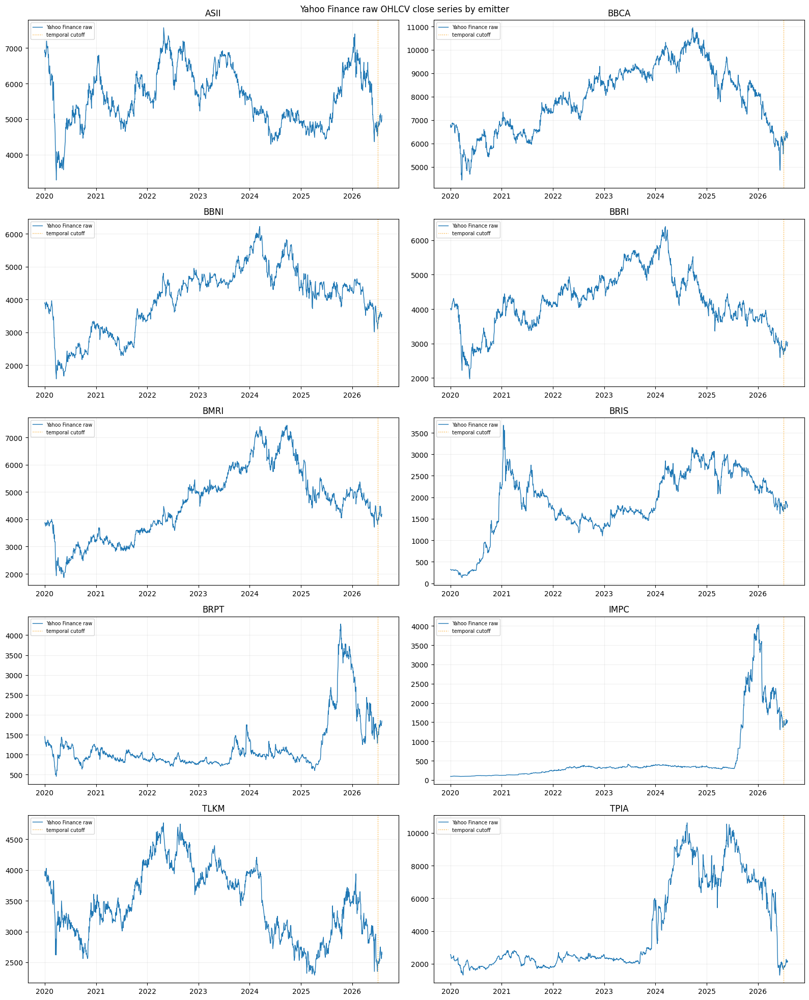

In [23]:
fig, axes = plt.subplots(5, 2, figsize=(16, 20), sharex=False)
for ax, ticker in zip(axes.flat, TICKERS):
    y = yahoo_raw[yahoo_raw.ticker.eq(ticker)]
    ax.plot(y.date, y.close, label='Yahoo Finance raw', linewidth=1)
    ax.axvline(pd.Timestamp('2026-07-01'), color='#f9a825', linestyle=':', linewidth=1, label='temporal cutoff')
    ax.set_title(ticker); ax.grid(alpha=.2); ax.legend(fontsize=7)
plt.suptitle('Yahoo Finance raw OHLCV close series by emitter'); plt.tight_layout(); plt.show()


### Penjelasan output

Grafik EDA close series digunakan untuk memeriksa bentuk data mentah, bukan untuk menyatakan performa model. Sepuluh panel harus menampilkan seluruh emiten dan cutoff temporal. Lonjakan, jeda, atau perubahan skala perlu diperiksa karena dapat memengaruhi return, normalisasi, dan interpretasi forecast.


## 5. Data Alignment dan Core Dataset Assembly
### 5.1 Panel Yahoo Finance yang selaras
### 5.2 Pemeriksaan integritas OHLCV

Bagian ini membentuk panel core dari data Yahoo Finance, menghitung return log, range, body, dan log volume, serta menampilkan ukuran dan rentang tanggal per emiten. Panel ini menjadi input preprocessing lanjutan.


In [24]:
core = yahoo_raw[yahoo_raw.ticker.isin(TICKERS)].copy()
core['log_return'] = core.groupby('ticker')['close'].transform(lambda s: np.log(s).diff())
core['range_pct'] = (core['high'] - core['low']) / core['close'].replace(0,np.nan)
core['body_pct'] = (core['close'] - core['open']) / core['open'].replace(0,np.nan)
core['log_volume'] = np.log1p(core['volume'].clip(lower=0))
core = core.replace([np.inf,-np.inf],np.nan)
print('Yahoo Finance core panel:')
display(core.head(10))
display(core.groupby('ticker').agg(rows=('date','size'),first=('date','min'),last=('date','max'),missing_close=('close',lambda s:s.isna().sum())).reindex(TICKERS))
print('Core source: Yahoo Finance raw OHLCV only.')

Yahoo Finance core panel:


,data_source,date,ticker,open,high,low,close,adjclose,volume,source,log_return,range_pct,body_pct,log_volume
0,YAHOO_FINANCE_RAW,2020-01-02,ASII,6925.0,6925.0,6775.0,6875.0,4415.803223,15008600,YAHOO_FINANCE_RAW,NaN,0.021818,-0.007220,16.524134
1,YAHOO_FINANCE_RAW,2020-01-03,ASII,6925.0,6950.0,6825.0,6950.0,4463.975586,19068800,YAHOO_FINANCE_RAW,0.010850,0.017986,0.003610,16.763564
2,YAHOO_FINANCE_RAW,2020-01-06,ASII,6900.0,6900.0,6750.0,6750.0,4335.516602,22261900,YAHOO_FINANCE_RAW,-0.029199,0.022222,-0.021739,16.918387
3,YAHOO_FINANCE_RAW,2020-01-07,ASII,6800.0,6825.0,6675.0,6775.0,4351.573730,27963000,YAHOO_FINANCE_RAW,0.003697,0.022140,-0.003676,17.146393
4,YAHOO_FINANCE_RAW,2020-01-08,ASII,6700.0,6825.0,6700.0,6775.0,4351.573730,15150400,YAHOO_FINANCE_RAW,0.000000,0.018450,0.011194,16.533538
5,YAHOO_FINANCE_RAW,2020-01-09,ASII,6800.0,6875.0,6750.0,6875.0,4415.803223,19691200,YAHOO_FINANCE_RAW,0.014652,0.018182,0.011029,16.795682
6,YAHOO_FINANCE_RAW,2020-01-10,ASII,6900.0,6925.0,6825.0,6825.0,4383.688965,17687600,YAHOO_FINANCE_RAW,-0.007299,0.014652,-0.010870,16.688374
7,YAHOO_FINANCE_RAW,2020-01-13,ASII,6850.0,6925.0,6825.0,6925.0,4447.918457,29585200,YAHOO_FINANCE_RAW,0.014546,0.014440,0.010949,17.202785
8,YAHOO_FINANCE_RAW,2020-01-14,ASII,6975.0,7175.0,6925.0,7175.0,4608.492676,41214400,YAHOO_FINANCE_RAW,0.035465,0.034843,0.028674,17.534298
9,YAHOO_FINANCE_RAW,2020-01-15,ASII,7150.0,7250.0,7025.0,7200.0,4624.550781,38535100,YAHOO_FINANCE_RAW,0.003478,0.031250,0.006993,17.467080


,rows,first,last,missing_close
ticker,,,,
ASII,1586,2020-01-02,2026-07-31,0
BBCA,1586,2020-01-02,2026-07-31,0
BBNI,1586,2020-01-02,2026-07-31,0
BBRI,1586,2020-01-02,2026-07-31,0
BMRI,1586,2020-01-02,2026-07-31,0
BRIS,1586,2020-01-02,2026-07-31,0
BRPT,1586,2020-01-02,2026-07-31,0
IMPC,1586,2020-01-02,2026-07-31,0
TLKM,1586,2020-01-02,2026-07-31,0


Core source: Yahoo Finance raw OHLCV only.


### Penjelasan output

Panel core menampilkan data Yahoo yang sudah disejajarkan dan fitur dasar seperti log return, range, body, serta log volume. Tabel per emiten menjawab berapa banyak observasi yang tersedia dan apakah ada missing close. Panel ini adalah bahan pembentukan fitur; belum merupakan tensor model dan belum merupakan hasil prediksi.


## 6. Feature Engineering Indikator Teknikal
### 6.1 Return dan volatilitas
### 6.2 ATR dan moving-average gap
### 6.3 Bollinger Bands
### 6.4 RSI
### 6.5 Posisi harga dan volume

Bagian ini membangun return multi-horizon, realized volatility, ATR, gap SMA, Bollinger Bands periode 21 dengan 2 standar deviasi, RSI14/RSI50, posisi close dalam range, dan volume z-score. Kolom mentah dan ringkasan numerik per emiten ditampilkan, bersama visual BB dan RSI untuk seluruh emiten.


Feature parameters: {'RSI_PERIOD': 14, 'RSI_DISPLAY_RANGE': '0-100 with levels 30/70', 'BB_LENGTH': 21, 'BB_STD': 2.0}
Numerical indicator transparency by issuer: one row per emiten


/tmp/ipykernel_58/3620266782.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f['atr14_pct'] = g.apply(lambda x: (x['high']-x['low']).rolling(14).mean()/x['close']).reset_index(level=0,drop=True)


,emiten,ret_1d__count,ret_1d__mean,ret_1d__std,ret_1d__min,ret_1d__median,ret_1d__max,ret_20d__count,ret_20d__mean,ret_20d__std,...,high_low_position__std,high_low_position__min,high_low_position__median,high_low_position__max,volume_z20__count,volume_z20__mean,volume_z20__std,volume_z20__min,volume_z20__median,volume_z20__max
0,ASII,1585,0.000047,0.021723,-0.114537,0.0,0.137931,1566,-0.000229,0.088698,...,0.335085,0.0,0.500000,1.0,1567,0.007395,1.035406,-2.910239,-0.236676,4.114814
1,BBCA,1585,0.000116,0.017469,-0.085294,0.0,0.173333,1566,0.001056,0.063625,...,0.367459,0.0,0.473684,1.0,1567,0.028783,1.044901,-2.849832,-0.246282,4.206805
2,BBNI,1585,0.000192,0.022558,-0.117188,0.0,0.136471,1566,0.004496,0.102139,...,0.325581,0.0,0.454545,1.0,1567,0.018383,1.058523,-2.495510,-0.271590,3.964057
3,BBRI,1585,0.000057,0.021629,-0.101235,0.0,0.204918,1566,-0.000501,0.088112,...,0.344128,0.0,0.428571,1.0,1567,0.011477,1.036743,-2.400689,-0.215542,4.069844
4,BMRI,1585,0.000294,0.022153,-0.129921,0.0,0.158031,1566,0.005075,0.085987,...,0.329998,0.0,0.500000,1.0,1567,0.015084,1.029180,-2.108647,-0.206163,4.018423
5,BRIS,1585,0.001726,0.036644,-0.144000,0.0,0.250000,1566,0.039177,0.202468,...,0.299411,0.0,0.375000,1.0,1567,-0.011831,1.068345,-1.813610,-0.340264,4.206173
6,BRPT,1585,0.000998,0.041783,-0.181818,0.0,0.247619,1566,0.026400,0.233589,...,0.323659,0.0,0.400000,1.0,1567,-0.008330,1.058073,-2.401775,-0.280323,4.179050
7,IMPC,1585,0.002178,0.029196,-0.150000,0.0,0.250000,1566,0.052734,0.227958,...,0.335789,0.0,0.666659,1.0,1567,0.047253,1.074338,-2.991569,-0.179701,4.234887
8,TLKM,1585,-0.000027,0.021146,-0.148551,0.0,0.137405,1566,-0.002446,0.074973,...,0.331873,0.0,0.444444,1.0,1567,0.022287,1.040605,-2.821285,-0.234219,4.177932
9,TPIA,1585,0.000555,0.036591,-0.200000,0.0,0.250000,1566,0.014946,0.181782,...,0.360413,0.0,0.500000,1.0,1567,0.005326,1.078391,-3.252082,-0.267560,4.181807


Raw indicator sample with issuer column:


,ticker,date,close,bb_mid_21,bb_upper_21,bb_lower_21,bb_width_21,rsi14,rsi50
0,ASII,2020-01-02,6875.000000,NaN,NaN,NaN,NaN,50.0,50.0
1,ASII,2020-01-03,6950.000000,NaN,NaN,NaN,NaN,50.0,50.0
2,ASII,2020-01-06,6750.000000,NaN,NaN,NaN,NaN,50.0,50.0
1586,BBCA,2020-01-02,6690.000000,NaN,NaN,NaN,NaN,50.0,50.0
1587,BBCA,2020-01-03,6800.000000,NaN,NaN,NaN,NaN,50.0,50.0
1588,BBCA,2020-01-06,6735.000000,NaN,NaN,NaN,NaN,50.0,50.0
3172,BBNI,2020-01-02,3887.500000,NaN,NaN,NaN,NaN,50.0,50.0
3173,BBNI,2020-01-03,3900.000000,NaN,NaN,NaN,NaN,50.0,50.0
3174,BBNI,2020-01-06,3812.500000,NaN,NaN,NaN,NaN,50.0,50.0
4758,BBRI,2020-01-02,4009.021729,NaN,NaN,NaN,NaN,50.0,50.0


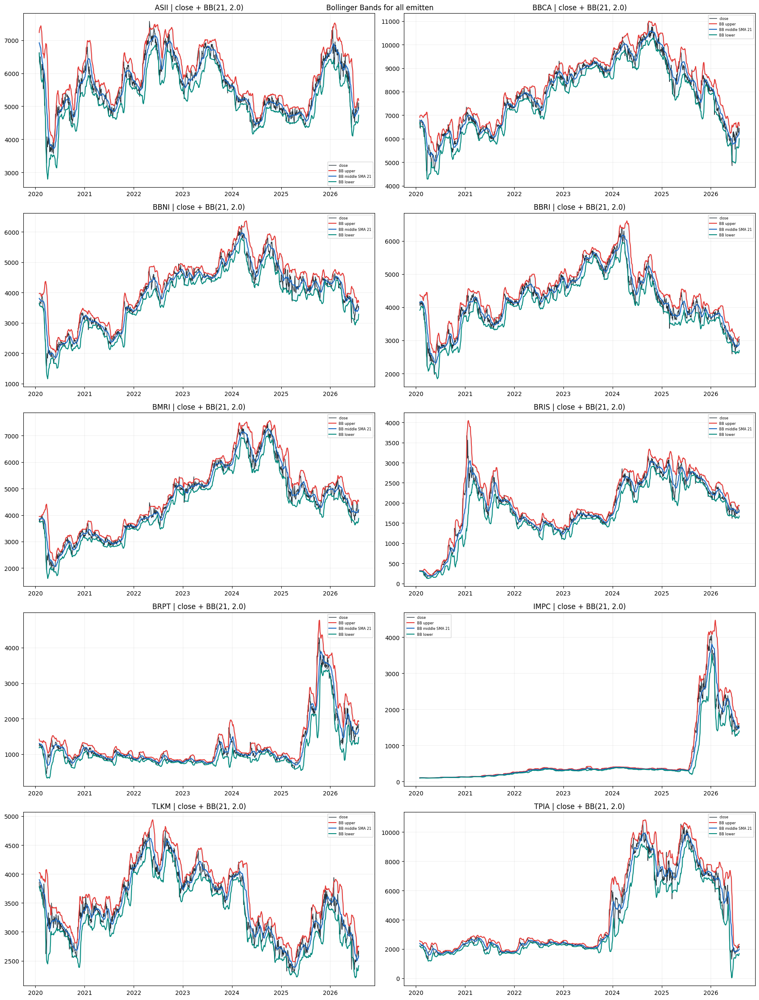

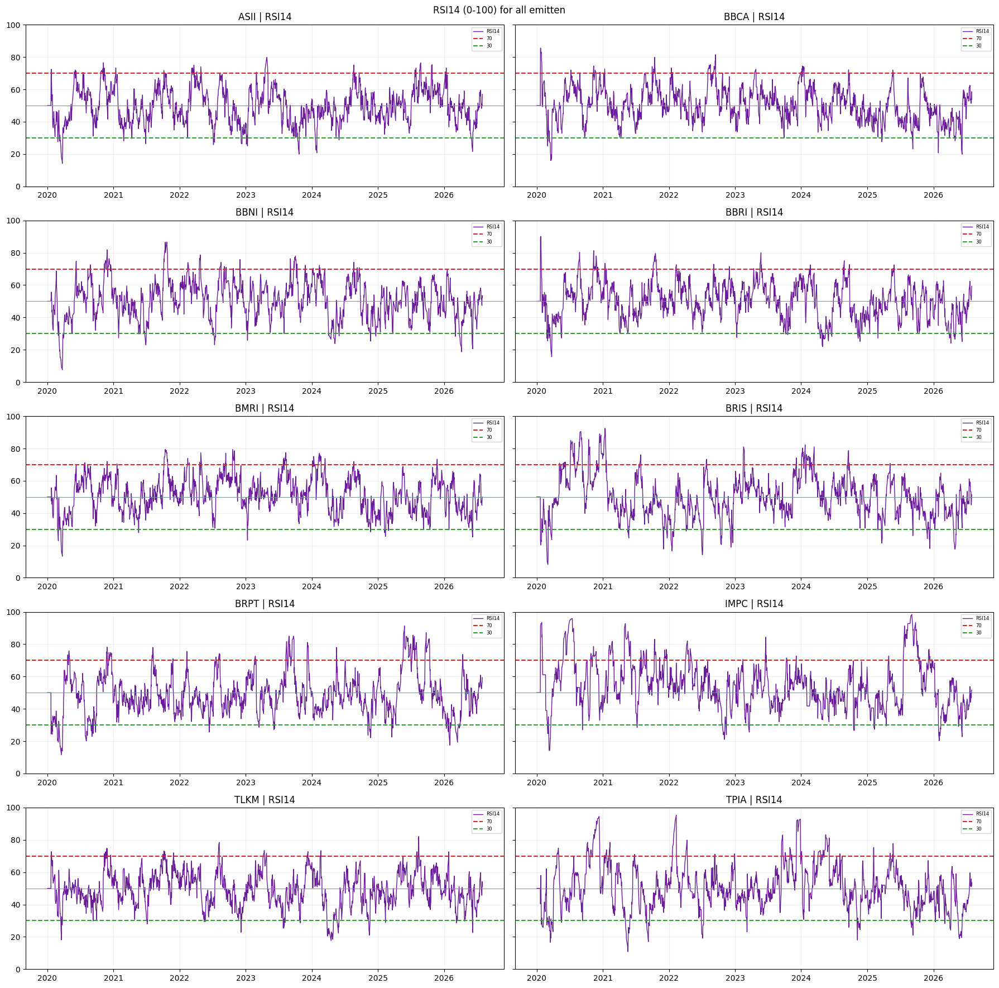

In [25]:
RSI_PERIOD = 14
BB_LENGTH = 21
BB_STD = 2.0

def rsi(series, period=14):
    delta = series.diff(); up = delta.clip(lower=0); down = -delta.clip(upper=0)
    gain = up.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    loss = down.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    rs = gain / loss.replace(0, np.nan)
    return (100 - (100 / (1 + rs))).fillna(50)

def add_features(frame):
    f = frame.sort_values(['ticker','date']).copy(); g = f.groupby('ticker', group_keys=False)
    f['ret_1d'] = g['close'].pct_change(); f['ret_20d'] = g['close'].pct_change(20); f['ret_60d'] = g['close'].pct_change(60)
    f['log_value'] = np.log1p(f['close'] * f['volume'].clip(lower=0))
    f['value_rel_21'] = f['close']*f['volume'] / g['close'].transform(lambda s:s.rolling(21).mean()).replace(0,np.nan)
    f['rv_20d'] = g['ret_1d'].transform(lambda s:s.rolling(20).std())
    f['atr14_pct'] = g.apply(lambda x: (x['high']-x['low']).rolling(14).mean()/x['close']).reset_index(level=0,drop=True)
    f['sma21_gap'] = f['close']/g['close'].transform(lambda s:s.rolling(21).mean())-1
    f['sma50_gap'] = f['close']/g['close'].transform(lambda s:s.rolling(50).mean())-1
    bb_mid = g['close'].transform(lambda s:s.rolling(BB_LENGTH).mean())
    bb_std = g['close'].transform(lambda s:s.rolling(BB_LENGTH).std())
    f['bb_mid_21'] = bb_mid; f['bb_upper_21'] = bb_mid + BB_STD*bb_std; f['bb_lower_21'] = bb_mid - BB_STD*bb_std
    f['bb_width_21'] = (f['bb_upper_21']-f['bb_lower_21']) / f['bb_mid_21'].replace(0,np.nan)
    f['rsi14'] = g['close'].transform(lambda s:rsi(s,RSI_PERIOD)); f['rsi50'] = g['close'].transform(lambda s:rsi(s,50))
    f['rsi14_centered'] = f['rsi14']-50; f['rsi50_centered'] = f['rsi50']-50
    f['high_low_position'] = (f['close']-f['low'])/(f['high']-f['low']).replace(0,np.nan)
    f['volume_z20'] = g['volume'].transform(lambda s:(s-s.rolling(20).mean())/s.rolling(20).std())
    return f.replace([np.inf,-np.inf],np.nan)

features = add_features(core)
FEATURES_BASE = ['ret_1d','ret_20d','ret_60d','log_value','value_rel_21','rv_20d','atr14_pct','sma21_gap','sma50_gap','bb_width_21','rsi14_centered','rsi50_centered','high_low_position','volume_z20']
print('Feature parameters:', {'RSI_PERIOD':RSI_PERIOD,'RSI_DISPLAY_RANGE':'0-100 with levels 30/70','BB_LENGTH':BB_LENGTH,'BB_STD':BB_STD})
indicator_cols=['ret_1d','ret_20d','ret_60d','rv_20d','atr14_pct','sma21_gap','sma50_gap','bb_width_21','rsi14','rsi50','high_low_position','volume_z20']
indicator_summary=features.groupby('ticker')[indicator_cols].agg(['count','mean','std','min','median','max']).round(6)
indicator_summary.columns=['__'.join(col) for col in indicator_summary.columns]
indicator_summary=indicator_summary.reset_index().rename(columns={'ticker':'emiten'})
print('Numerical indicator transparency by issuer: one row per emiten')
display(indicator_summary)
print('Raw indicator sample with issuer column:')
display(features[['ticker','date','close','bb_mid_21','bb_upper_21','bb_lower_21','bb_width_21','rsi14','rsi50']].sort_values(['ticker','date']).groupby('ticker').head(3))
fig,axes=plt.subplots(5,2,figsize=(18,24),sharex=False)
for ax,ticker in zip(axes.flat,TICKERS):
    sample=features[features.ticker.eq(ticker)].dropna(subset=['bb_mid_21','bb_upper_21','bb_lower_21'])
    x=sample['date'].to_numpy(); close=sample['close'].to_numpy(); upper=sample['bb_upper_21'].to_numpy(); mid=sample['bb_mid_21'].to_numpy(); lower=sample['bb_lower_21'].to_numpy()
    ax.plot(x,close,label='close',color='#263238',linewidth=1); ax.plot(x,upper,label='BB upper',color='#e53935'); ax.plot(x,mid,label='BB middle SMA 21',color='#1565c0'); ax.plot(x,lower,label='BB lower',color='#00897b'); ax.fill_between(x,lower,upper,color='#90caf9',alpha=.12); ax.set_title(f'{ticker} | close + BB(21, 2.0)'); ax.grid(alpha=.2); ax.legend(fontsize=6)
plt.suptitle('Bollinger Bands for all emitten'); plt.tight_layout(); plt.show()
fig,axes=plt.subplots(5,2,figsize=(18,18),sharex=False,sharey=True)
for ax,ticker in zip(axes.flat,TICKERS):
    sample=features[features.ticker.eq(ticker)].dropna(subset=['rsi14']); x=sample['date'].to_numpy(); values=sample['rsi14'].to_numpy()
    ax.plot(x,values,label='RSI14',color='#6a1b9a',linewidth=1); ax.axhline(70,color='#d62728',linestyle='--',label='70'); ax.axhline(30,color='#2ca02c',linestyle='--',label='30'); ax.axhline(50,color='#78909c',linewidth=.7); ax.set_ylim(0,100); ax.set_title(f'{ticker} | RSI14'); ax.grid(alpha=.2); ax.legend(fontsize=6)
plt.suptitle('RSI14 (0-100) for all emitten'); plt.tight_layout(); plt.show()


### Penjelasan output

Ringkasan indikator memperlihatkan statistik numerik per emiten agar pembaca dapat menilai skala dan variasi fitur. Grafik Bollinger Bands menunjukkan close terhadap middle/upper/lower band, sedangkan RSI14 memakai rentang 0-100 dengan level 30 dan 70. Nilai tinggi atau rendah hanya menggambarkan kondisi indikator, bukan probabilitas Buy/Sell.


## 7. Fibonacci Feature Engineering Timestamp-Safe (Augmented)
### 7.1 Rolling anchor dan level Fibonacci
### 7.2 Jarak harga terhadap level
### 7.3 Kontrak fitur jalur augmented

Bagian ini menambahkan fitur Fibonacci hanya pada jalur augmented. Level dihitung dari informasi yang tersedia sampai setiap timestamp; hasilnya tidak digunakan sebagai label ex-post dan tidak mengubah jalur baseline.


Baseline feature count: 14 | augmented feature count: 18


,ticker,date,ret_1d,ret_20d,ret_60d,log_value,value_rel_21,rv_20d,atr14_pct,sma21_gap,sma50_gap,bb_width_21,rsi14_centered,rsi50_centered,high_low_position,volume_z20,fib_dist_382,fib_dist_500,fib_dist_618,fib_zone_touch
15850,TPIA,2026-07-20,0.089974,0.098446,-0.656680,28.165612,9.207896e+08,0.050278,0.047338,0.143738,-0.069032,0.243699,4.155160,-9.254377,0.942857,2.140564,-0.684665,-1.029481,-1.374297,0.0
15851,TPIA,2026-07-21,0.061321,0.097561,-0.634146,28.464650,1.231616e+09,0.050228,0.047302,0.203975,0.017087,0.303264,8.653190,-8.327631,0.772727,2.533915,-0.587329,-0.912222,-1.237116,0.0
15852,TPIA,2026-07-22,0.013333,0.270195,-0.620000,28.147965,8.920782e+08,0.039781,0.046679,0.212920,0.057122,0.348105,9.637368,-8.113604,0.562500,1.325556,-0.566443,-0.887061,-1.207680,0.0
15853,TPIA,2026-07-23,-0.048246,0.148148,-0.622609,28.107224,8.484051e+08,0.040826,0.053983,0.143538,0.033727,0.366794,4.513563,-8.680876,0.047619,1.264358,-0.645848,-0.982719,-1.319590,0.0
15854,TPIA,2026-07-24,-0.032258,0.169916,-0.621622,27.855193,6.559414e+08,0.039662,0.056633,0.100849,0.021798,0.376378,1.482311,-9.041079,0.714286,0.628187,-0.700710,-1.048810,-1.396910,0.0
15855,TPIA,2026-07-27,-0.004762,0.222222,-0.605660,27.097316,3.051665e+08,0.037588,0.058100,0.087598,0.039284,0.378362,1.045631,-9.093062,0.444444,-0.652462,-0.708847,-1.058612,-1.408378,0.0
15856,TPIA,2026-07-28,0.000000,0.262840,-0.605660,27.009891,2.770117e+08,0.036322,0.058100,0.077452,0.062640,0.368152,1.045631,-9.093062,0.400000,-0.710687,-0.708847,-1.058612,-1.408378,0.0
15857,TPIA,2026-07-29,0.052632,0.309524,-0.566502,27.993593,7.310423e+08,0.037424,0.059091,0.119186,0.135425,0.355367,5.825723,-8.246363,0.809524,0.826985,-0.623405,-0.955682,-1.287959,0.0
15858,TPIA,2026-07-30,-0.040909,0.192090,-0.652675,27.766964,5.767910e+08,0.038153,0.063135,0.062335,0.100449,0.331024,1.403206,-8.739931,0.181818,0.370996,-0.692649,-1.039100,-1.385550,0.0
15859,TPIA,2026-07-31,0.023697,0.210084,-0.661176,27.080529,2.876482e+08,0.038283,0.060351,0.077435,0.132432,0.320663,3.602300,-8.348922,0.666667,-0.713838,-0.653468,-0.991898,-1.330329,0.0


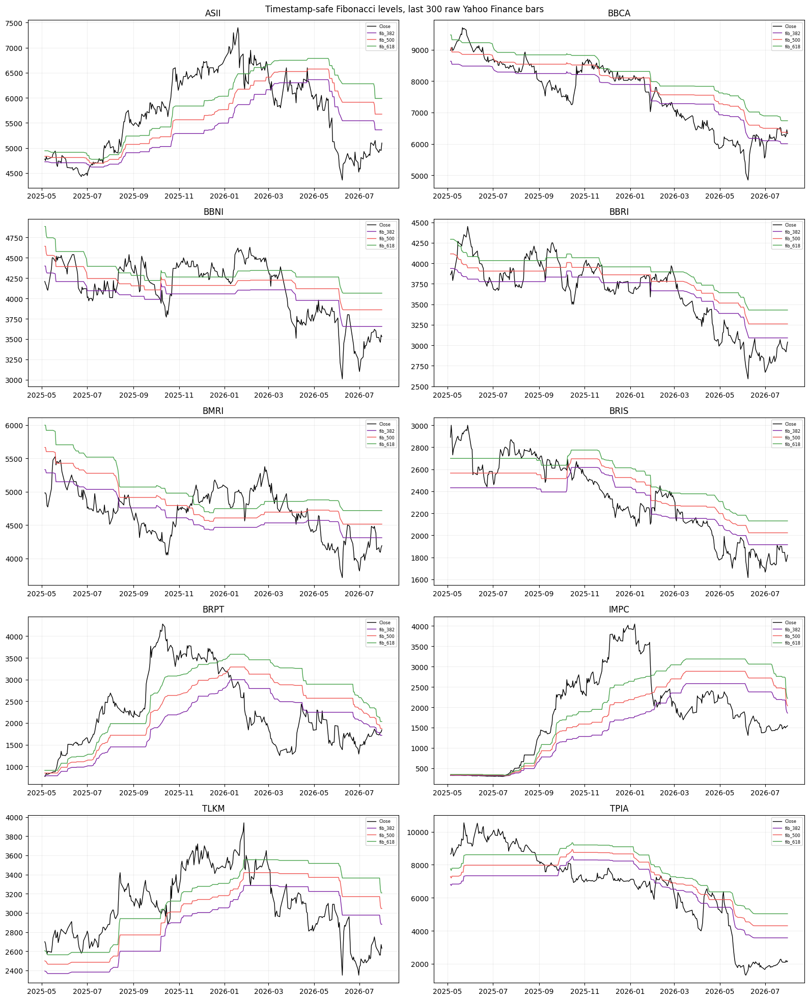

In [26]:
def add_fibonacci_features(frame, lookback=120):
    f=frame.sort_values(['ticker','date']).copy(); out=[]
    for ticker, group in f.groupby('ticker'):
        group=group.copy(); low=group['low'].rolling(lookback,min_periods=lookback).min(); high=group['high'].rolling(lookback,min_periods=lookback).max(); span=(high-low).replace(0,np.nan)
        group['fib_382'] = low + .382*span; group['fib_500']=low+.5*span; group['fib_618']=low+.618*span
        group['fib_dist_382']=(group.close-group.fib_382)/group.close; group['fib_dist_500']=(group.close-group.fib_500)/group.close; group['fib_dist_618']=(group.close-group.fib_618)/group.close
        group['fib_zone_touch'] = ((group.low <= group.fib_618)&(group.high >= group.fib_382)).astype(float)
        out.append(group)
    return pd.concat(out).sort_values(['ticker','date'])

features_aug=add_fibonacci_features(features)
FEATURES_AUG=FEATURES_BASE+['fib_dist_382','fib_dist_500','fib_dist_618','fib_zone_touch']
print('Baseline feature count:',len(FEATURES_BASE),'| augmented feature count:',len(FEATURES_AUG))
display(features_aug[['ticker','date']+FEATURES_AUG].tail(10))
fig, axes=plt.subplots(5,2,figsize=(16,20))
for ax,ticker in zip(axes.flat,TICKERS):
    s=features_aug[features_aug.ticker.eq(ticker)].tail(300)
    ax.plot(s.date,s.close,color='black',linewidth=1,label='Close')
    for col,color in [('fib_382','#7b1fa2'),('fib_500','#ef5350'),('fib_618','#43a047')]: ax.plot(s.date,s[col],color=color,linewidth=1,label=col)
    ax.set_title(ticker); ax.grid(alpha=.2); ax.legend(fontsize=6)
plt.suptitle('Timestamp-safe Fibonacci levels, last 300 raw Yahoo Finance bars'); plt.tight_layout(); plt.show()

### Penjelasan output

Fitur Fibonacci augmented menunjukkan informasi tambahan yang hanya tersedia pada jalur augmented. Fitur harus dibangun dari data sampai timestamp tersebut agar tidak memakai masa depan. Perbandingan baseline versus augmented bertujuan menguji apakah fitur ini membantu; Fibonacci tidak otomatis berarti forecast lebih akurat.


## 8. Sequence Window Construction
### 8.1 Context 120 hari dan target 60 hari
### 8.2 Penyelarasan baseline dan augmented

Bagian ini mengubah feature table menjadi context window 120 hari dan target future-return path 60 hari. Baseline dan augmented disejajarkan berdasarkan ticker, decision date, dan target end date agar perbandingan adil.


In [27]:
def build_window_records(frame, feature_cols):
    records={}
    for ticker, group in frame.groupby('ticker'):
        group=group.sort_values('date').dropna(subset=feature_cols+['log_return']).reset_index(drop=True)
        values=group[feature_cols].to_numpy('float32'); returns=group['log_return'].to_numpy('float32')
        for end in range(L-1, len(group)-H):
            key=(ticker,str(group.loc[end,'date'].date()),str(group.loc[end+H,'date'].date()))
            records[key]=(values[end-L+1:end+1],returns[end+1:end+1+H])
    return records

def stack_window_records(records, keys):
    contexts=[records[key][0] for key in keys]; targets=[records[key][1] for key in keys]
    meta=pd.DataFrame([{'ticker':key[0],'decision_date':key[1],'target_end_date':key[2]} for key in keys])
    return np.stack(contexts),np.stack(targets),meta

base_records=build_window_records(features,FEATURES_BASE)
aug_records=build_window_records(features_aug,FEATURES_AUG)
common_keys=sorted(set(base_records).intersection(aug_records),key=lambda key:(key[0],key[1],key[2]))
assert common_keys, 'No common baseline/augmented windows found'
base_context,base_target,base_meta=stack_window_records(base_records,common_keys)
aug_context,aug_target,aug_meta=stack_window_records(aug_records,common_keys)
assert base_meta[['ticker','decision_date','target_end_date']].equals(aug_meta[['ticker','decision_date','target_end_date']])
print('Baseline context:',base_context.shape,'target:',base_target.shape)
print('Augmented context:',aug_context.shape,'target:',aug_target.shape)
print('Common aligned windows:',len(common_keys))
display(base_meta.groupby('ticker').size().rename('window_count').to_frame())
display(base_meta.head(10))


Baseline context: (12822, 120, 14) target: (12822, 60)
Augmented context: (12822, 120, 18) target: (12822, 60)
Common aligned windows: 12822


,window_count
ticker,
ASII,1283
BBCA,1284
BBNI,1284
BBRI,1284
BMRI,1284
BRIS,1284
BRPT,1284
IMPC,1268
TLKM,1284


,ticker,decision_date,target_end_date
0,ASII,2020-12-23,2021-03-25
1,ASII,2020-12-28,2021-03-26
2,ASII,2020-12-29,2021-03-29
3,ASII,2020-12-30,2021-03-30
4,ASII,2021-01-04,2021-03-31
5,ASII,2021-01-05,2021-04-01
6,ASII,2021-01-06,2021-04-05
7,ASII,2021-01-07,2021-04-06
8,ASII,2021-01-08,2021-04-07
9,ASII,2021-01-11,2021-04-08


### Penjelasan output

Ukuran context dan target menjelaskan bentuk input model: 120 hari historis menjadi kondisi, lalu 60 trading days menjadi target future-return path. `Common aligned windows` memastikan baseline dan augmented diuji pada tanggal dan emiten yang sama. Jika jumlah atau metadata tidak sama, evaluasi komparatif tidak valid.


## 9. Temporal Data Split dan External Post-Cutoff Seal
### 9.1 Development train-validation-assessment split
### 9.2 External post-cutoff seal

Bagian ini membagi window development menjadi train, validation, dan assessment berdasarkan waktu. Window yang targetnya melewati cutoff atau berada setelah cutoff disegel dan tidak masuk evaluasi development.


In [28]:
dates=pd.to_datetime(base_meta.decision_date)
target_end_dates=pd.to_datetime(base_meta.target_end_date)
cutoff=pd.Timestamp('2026-07-01')
tickers=base_meta.ticker.astype(str).to_numpy()
eligible_dev_mask=((dates<=cutoff)&(target_end_dates<=cutoff)).to_numpy()
post_cutoff_mask=(dates>cutoff).to_numpy()
incomplete_target_mask=((dates<=cutoff)&(target_end_dates>cutoff)).to_numpy()
dev_dates=dates[eligible_dev_mask]
q60=dev_dates.quantile(.60); q80=dev_dates.quantile(.80)
train_mask=(eligible_dev_mask&(dates<q60).to_numpy())
validation_mask=(eligible_dev_mask&(dates>=q60).to_numpy()&(dates<q80).to_numpy())
assessment_mask=(eligible_dev_mask&(dates>=q80).to_numpy())
split_df=pd.DataFrame({'split':['train','validation','assessment','incomplete_target_sealed','post_cutoff_sealed'], 'rows':[train_mask.sum(),validation_mask.sum(),assessment_mask.sum(),incomplete_target_mask.sum(),post_cutoff_mask.sum()], 'role':['fit model parameters','monitor training and freeze configuration','development-only scoring after selection is frozen','not eligible: 60-day target crosses cutoff','not eligible: decision date is after cutoff']})
split_df['share_of_all_windows']=split_df['rows']/len(base_meta)
display(split_df)
per_ticker_rows=[]
for ticker in sorted(set(tickers)):
    ticker_mask=tickers==ticker
    per_ticker_rows.append({'ticker':ticker,'train':int((train_mask&ticker_mask).sum()),'validation':int((validation_mask&ticker_mask).sum()),'assessment':int((assessment_mask&ticker_mask).sum()),'incomplete_target_sealed':int((incomplete_target_mask&ticker_mask).sum()),'post_cutoff_sealed':int((post_cutoff_mask&ticker_mask).sum())})
per_ticker_split=pd.DataFrame(per_ticker_rows)
display(per_ticker_split)
first_incomplete=dates[incomplete_target_mask].min() if incomplete_target_mask.any() else pd.NaT
first_post_cutoff=dates[post_cutoff_mask].min() if post_cutoff_mask.any() else pd.NaT
print('Yahoo-only temporal policy:', {'source':'Yahoo Finance raw OHLCV','cutoff':str(cutoff.date()),'development_last_decision_date':str(dev_dates.max().date()),'first_incomplete_target_date':None if pd.isna(first_incomplete) else str(first_incomplete.date()),'first_post_cutoff_decision_date':None if pd.isna(first_post_cutoff) else str(first_post_cutoff.date()),'final_holdout_accessed':False})
print('Only windows whose full 60-day target ends on or before the cutoff enter development evaluation.')
print('Incomplete targets and post-cutoff windows are sealed from training, validation, and assessment; they are reserved for the separate cutoff forecast or external paper replay.')
print('The cutoff forecast uses the last 120-day context ending at the cutoff and is not treated as a development row.')
assert train_mask.sum()>0 and validation_mask.sum()>0 and assessment_mask.sum()>0
assert not np.any(train_mask & post_cutoff_mask)
assert not np.any(validation_mask & post_cutoff_mask)
assert not np.any(assessment_mask & post_cutoff_mask)

,split,rows,role,share_of_all_windows
0,train,7558,fit model parameters,0.589456
1,validation,2520,monitor training and freeze configuration,0.196537
2,assessment,2524,development-only scoring after selection is fr...,0.196849
3,incomplete_target_sealed,220,not eligible: 60-day target crosses cutoff,0.017158
4,post_cutoff_sealed,0,not eligible: decision date is after cutoff,0.000000


,ticker,train,validation,assessment,incomplete_target_sealed,post_cutoff_sealed
0,ASII,755,252,254,22,0
1,BBCA,756,252,254,22,0
2,BBNI,756,252,254,22,0
3,BBRI,756,252,254,22,0
4,BMRI,756,252,254,22,0
5,BRIS,756,252,254,22,0
6,BRPT,756,252,254,22,0
7,IMPC,756,252,238,22,0
8,TLKM,756,252,254,22,0
9,TPIA,755,252,254,22,0


Yahoo-only temporal policy: {'source': 'Yahoo Finance raw OHLCV', 'cutoff': '2026-07-01', 'development_last_decision_date': '2026-03-27', 'first_incomplete_target_date': '2026-03-30', 'first_post_cutoff_decision_date': None, 'final_holdout_accessed': False}
Only windows whose full 60-day target ends on or before the cutoff enter development evaluation.
Incomplete targets and post-cutoff windows are sealed from training, validation, and assessment; they are reserved for the separate cutoff forecast or external paper replay.
The cutoff forecast uses the last 120-day context ending at the cutoff and is not treated as a development row.


### Penjelasan output

Section ini memisahkan data Yahoo secara temporal dengan cutoff 2026-07-01. Tabel pertama menjelaskan jumlah, proporsi, dan peran train, validation, assessment, serta dua kelompok sealed; tabel kedua memeriksa keseimbangan per emiten. Hanya window dengan target 60 hari penuh yang berakhir pada atau sebelum cutoff boleh masuk development. Window yang targetnya melewati cutoff dan window setelah cutoff tidak digunakan untuk fitting, validation, atau assessment. Forecast pada cutoff dibuat terpisah dari context 120 hari terakhir, sedangkan final holdout tetap terkunci dan tidak diakses.


## 10. Train-only Normalization dan Tensor Inspection
### 10.1 Statistik train-only
### 10.2 Shape, mask, dan alignment checks

Bagian ini menghitung mean/std hanya dari train split, menerapkan normalisasi ke train/validation/assessment, dan memeriksa bentuk tensor serta metadata. Statistik assessment tidak boleh memengaruhi fitting normalizer.


In [29]:
def normalize_variants(context, train_mask):
    mean=context[train_mask].mean(axis=(0,1),keepdims=True); std=context[train_mask].std(axis=(0,1),keepdims=True); std=np.where(std<1e-6,1,std)
    return ((context-mean)/std).astype('float32'),mean,std

base_x,base_mean,base_std=normalize_variants(base_context,train_mask)
aug_x,aug_mean,aug_std=normalize_variants(aug_context,train_mask)
print('Baseline tensor created in this notebook:',base_x.shape)
print('Augmented tensor created in this notebook:',aug_x.shape)
display(pd.DataFrame({'variant':['baseline','augmented'],'context_shape':[str(base_x.shape),str(aug_x.shape)],'target_shape':[str(base_target.shape),str(aug_target.shape)],'feature_count':[len(FEATURES_BASE),len(FEATURES_AUG)]}))
display(pd.DataFrame({'feature':FEATURES_BASE,'train_mean':base_mean.reshape(-1),'train_std':base_std.reshape(-1)}))

Baseline tensor created in this notebook: (12822, 120, 14)
Augmented tensor created in this notebook: (12822, 120, 18)


,variant,context_shape,target_shape,feature_count
0,baseline,"(12822, 120, 14)","(12822, 60)",14
1,augmented,"(12822, 120, 18)","(12822, 60)",18


,feature,train_mean,train_std
0,ret_1d,9.224908e-04,2.181999e-02
1,ret_20d,1.911632e-02,1.079807e-01
2,ret_60d,6.277020e-02,2.289440e-01
3,log_value,2.555375e+01,1.615624e+00
4,value_rel_21,7.698781e+07,8.298358e+07
5,rv_20d,1.942764e-02,1.003092e-02
6,atr14_pct,2.658651e-02,1.247721e-02
7,sma21_gap,7.657948e-03,5.730373e-02
8,sma50_gap,1.933140e-02,9.266200e-02
9,bb_width_21,1.321883e-01,1.039494e-01


### Penjelasan output

Output normalisasi menunjukkan statistik yang dihitung dari train saja serta bentuk tensor setelah transformasi. Mean/std train dipakai ulang ke validation dan assessment agar evaluasi tidak bocor. Nilai ekstrem atau tensor kosong biasanya menandakan masalah missing value, urutan fitur, atau alignment metadata.


## 11. Conditional Diffusion Model Architecture
### 11.1 Context encoder
### 11.2 Noise schedule
### 11.3 Denoising head

Bagian ini mendefinisikan conditional diffusion model, noise schedule, encoder context, time embedding, dan denoising head. Model menghasilkan future-return paths, bukan label Buy/Sell/Hold langsung.


In [30]:
STEPS=32
class ConditionalDiffusion(nn.Module):
    def __init__(self,features):
        super().__init__(); self.encoder=nn.GRU(features,64,batch_first=True); self.time=nn.Embedding(STEPS,64); self.path=nn.Linear(H,64); self.head=nn.Sequential(nn.Linear(192,128),nn.SiLU(),nn.Linear(128,H))
    def forward(self,noisy,context,step):
        _,h=self.encoder(context); return self.head(torch.cat([h[-1],self.path(noisy),self.time(step)],dim=1))

def schedule(device):
    beta=torch.linspace(1e-4,.02,STEPS,device=device); alpha=1-beta; return beta,alpha,torch.cumprod(alpha,0)

def train_model(context,target,train_mask,val_mask,gpu_id,variant):
    device=torch.device(f'cuda:{gpu_id}'); model=ConditionalDiffusion(context.shape[2]).to(device); opt=torch.optim.AdamW(model.parameters(),lr=2e-4); beta,alpha,abar=schedule(device); x=torch.from_numpy(context); y=torch.from_numpy(target); xt=x[train_mask].to(device); yt=y[train_mask].to(device); xv=x[val_mask].to(device); yv=y[val_mask].to(device); history=[]; started=time.monotonic()
    for epoch in range(1,EPOCHS+1):
        model.train(); order=torch.randperm(len(xt),device=device); losses=[]
        for start in range(0,len(order),128):
            if time.monotonic()-started>MAX_MINUTES*60: raise TimeoutError('training exceeded 30-minute bound')
            ix=order[start:start+128]; step=torch.randint(0,STEPS,(len(ix),),device=device); noise=torch.randn_like(yt[ix]); noisy=abar[step].sqrt()[:,None]*yt[ix]+(1-abar[step]).sqrt()[:,None]*noise; pred=model(noisy,xt[ix],step); loss=((pred-noise)**2).mean(); opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1); opt.step(); losses.append(float(loss.detach().cpu()))
        model.eval(); val_losses=[]
        with torch.no_grad():
            for start in range(0,len(xv),128):
                yy=yv[start:start+128]; step=torch.randint(0,STEPS,(len(yy),),device=device); noise=torch.randn_like(yy); noisy=abar[step].sqrt()[:,None]*yy+(1-abar[step]).sqrt()[:,None]*noise; val_losses.append(float(((model(noisy,xv[start:start+128],step)-noise)**2).mean().cpu()))
        history.append({'variant':variant,'epoch':epoch,'train_loss':np.mean(losses),'validation_loss':np.mean(val_losses)}); print(history[-1])
    return model, pd.DataFrame(history), device

### Penjelasan output

Cell arsitektur biasanya tidak menghasilkan tabel besar karena tugasnya mendefinisikan model. Output pentingnya adalah konfirmasi parameter model, jumlah diffusion steps, dimensi context, horizon, dan jumlah fitur. Model ini memprediksi distribusi future-return paths; Buy/Hold/Sell bukan output langsung dari denoising network.


## 12. Model Training dan Training Diagnostics
### 12.1 Dual-GPU training
### 12.2 Loss tracking
### 12.3 Training diagnostics

Bagian ini melatih baseline dan augmented secara terpisah pada dua GPU T4, dengan seed dan konfigurasi sama. Loss train/validation, ringkasan epoch terakhir, dan best validation loss ditampilkan untuk memeriksa proses belajar.


['Tesla T4', 'Tesla T4']
{'variant': 'baseline', 'epoch': 1, 'train_loss': np.float64(1.0029865483442941), 'validation_loss': np.float64(0.988455918431282)}
{'variant': 'augmented', 'epoch': 1, 'train_loss': np.float64(1.0043136288722356), 'validation_loss': np.float64(0.9888966232538223)}
{'variant': 'baseline', 'epoch': 2, 'train_loss': np.float64(0.9867899030447006), 'validation_loss': np.float64(0.9679202288389206)}
{'variant': 'augmented', 'epoch': 2, 'train_loss': np.float64(0.9875076889991761), 'validation_loss': np.float64(0.9692787200212478)}
{'variant': 'baseline', 'epoch': 3, 'train_loss': np.float64(0.9676072140534718), 'validation_loss': np.float64(0.9572881877422332)}
{'variant': 'augmented', 'epoch': 3, 'train_loss': np.float64(0.9690449297428131), 'validation_loss': np.float64(0.9597469091415405)}
{'variant': 'baseline', 'epoch': 4, 'train_loss': np.float64(0.9443139404058456), 'validation_loss': np.float64(0.9244629740715027)}
{'variant': 'augmented', 'epoch': 4, 'trai

,variant,epoch,train_loss,validation_loss
0,baseline,1,1.002987,0.988456
1,baseline,2,0.986790,0.967920
2,baseline,3,0.967607,0.957288
3,baseline,4,0.944314,0.924463
4,baseline,5,0.899591,0.862130
5,baseline,6,0.818829,0.775019
6,baseline,7,0.739629,0.700766
7,baseline,8,0.674149,0.655240
8,baseline,9,0.626203,0.600674
9,baseline,10,0.588240,0.569198


Training summary: final and best validation results per experiment


,variant,epochs_run,final_train_loss,final_validation_loss,best_validation_loss,best_validation_epoch
0,baseline,20,0.371046,0.368643,0.368643,20
1,augmented,20,0.375695,0.375023,0.375023,20


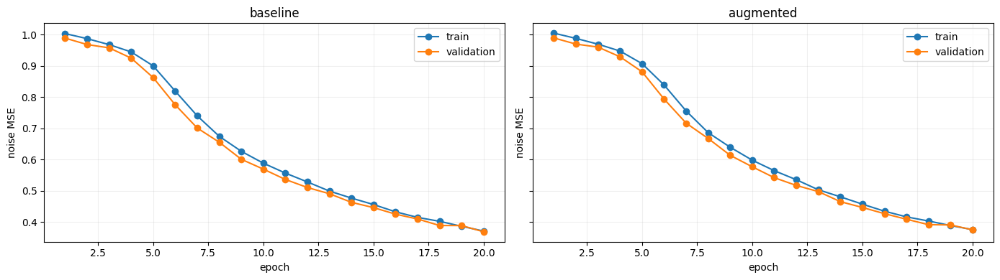

In [31]:
from concurrent.futures import ThreadPoolExecutor
assert torch.cuda.is_available() and torch.cuda.device_count()>=2
print([torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
jobs=[(base_x,base_target,train_mask,validation_mask,0,'baseline'),(aug_x,aug_target,train_mask,validation_mask,1,'augmented')]
with ThreadPoolExecutor(max_workers=2) as pool:
    futures=[pool.submit(train_model,*job) for job in jobs]
    base_model,base_history,base_device=futures[0].result()
    aug_model,aug_history,aug_device=futures[1].result()
loss_history=pd.concat([base_history,aug_history],ignore_index=True)
display(loss_history.round(6))
training_summary=pd.DataFrame([
    {'variant':'baseline','epochs_run':len(base_history),'final_train_loss':float(base_history.train_loss.iloc[-1]),'final_validation_loss':float(base_history.validation_loss.iloc[-1]),'best_validation_loss':float(base_history.validation_loss.min()),'best_validation_epoch':int(base_history.loc[base_history.validation_loss.idxmin(),'epoch'])},
    {'variant':'augmented','epochs_run':len(aug_history),'final_train_loss':float(aug_history.train_loss.iloc[-1]),'final_validation_loss':float(aug_history.validation_loss.iloc[-1]),'best_validation_loss':float(aug_history.validation_loss.min()),'best_validation_epoch':int(aug_history.loc[aug_history.validation_loss.idxmin(),'epoch'])},
])
print('Training summary: final and best validation results per experiment')
display(training_summary.round(6))
fig,axes=plt.subplots(1,2,figsize=(14,4),sharey=True)
for ax,(name,history) in zip(axes,[('baseline',base_history),('augmented',aug_history)]):
    ax.plot(history.epoch,history.train_loss,marker='o',label='train'); ax.plot(history.epoch,history.validation_loss,marker='o',label='validation'); ax.set_title(name); ax.set_xlabel('epoch'); ax.set_ylabel('noise MSE'); ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()


### Penjelasan output

Tabel training loss berisi train loss dan validation loss per epoch untuk baseline dan augmented. Loss yang turun menunjukkan optimisasi berjalan, tetapi validation loss yang lebih rendah tidak otomatis membuktikan generalisasi final. Grafik membantu melihat overfitting, plateau, atau perbedaan jalur; best validation loss dicatat untuk audit.


## 13. Probabilistic Forecast Generation dan Numerical Evaluation
### 13.1 Sampling forecast paths
### 13.2 CRPS, energy score, coverage, dan sharpness
### 13.3 Point-error diagnostics

Bagian ini menghasilkan 16 stochastic forecast paths untuk horizon 60 trading days dan menghitung CRPS, energy score, coverage, sharpness, PIT/rank, MAE, MSE, dan RMSE pada assessment development-only serta forecast cutoff.


In [32]:
def sample_paths(model,context,gpu_id):
    device=torch.device(f'cuda:{gpu_id}'); model.eval(); _,alpha,abar=schedule(device); generator=torch.Generator(device=device).manual_seed(SEED); out=[]; x=torch.from_numpy(context).to(device)
    with torch.no_grad():
        for _ in range(PATH_SAMPLES):
            paths=torch.randn((len(x),H),generator=generator,device=device)
            for step_i in range(STEPS-1,-1,-1):
                step=torch.full((len(x),),step_i,dtype=torch.long,device=device); eps=model(paths,x,step); mean=(paths-((1-alpha[step_i])/torch.sqrt(1-abar[step_i]))*eps)/torch.sqrt(alpha[step_i]); paths=mean+torch.sqrt(1-alpha[step_i])*torch.randn(paths.shape,generator=generator,device=device) if step_i else mean
            out.append(paths.cpu().numpy())
    return np.stack(out,axis=1)

def score(paths,actual):
    crps=np.mean([np.mean(abs(s-t))-.5*np.mean(abs(s[:,None]-s[None,:])) for s,t in zip(paths,actual)])
    energy=np.mean([np.mean(np.linalg.norm(s-t,axis=1))-.5*np.mean(np.linalg.norm(s[:,None]-s[None,:],axis=2)) for s,t in zip(paths,actual)])
    lo,hi=np.quantile(paths,[.1,.9],axis=1); coverage=np.mean((actual>=lo)&(actual<=hi)); sharpness=np.mean(hi-lo); pit=np.mean(paths<=actual[:,None,:])
    point=paths.mean(axis=1); err=point-actual
    return {'mean_crps':crps,'mean_energy_score':energy,'coverage_80':coverage,'sharpness_80':sharpness,'mean_pit_rank':pit,'MAE':np.mean(abs(err)),'MSE':np.mean(err**2),'RMSE':np.sqrt(np.mean(err**2))}

assessment_idx=np.flatnonzero(assessment_mask); base_paths=sample_paths(base_model,base_x[assessment_idx],0); aug_paths=sample_paths(aug_model,aug_x[assessment_idx],1); actual=base_target[assessment_idx]
metrics_df=pd.DataFrame([{'variant':'baseline',**score(base_paths,actual)},{'variant':'augmented',**score(aug_paths,actual)}]).set_index('variant')
display(metrics_df.round(6))

def cutoff_context(frame,feature_cols,cutoff):
    rows=[]
    for ticker in TICKERS:
        group=frame[(frame.ticker==ticker)&(frame.date<=cutoff)].sort_values('date').dropna(subset=feature_cols).tail(L)
        if len(group)!=L: raise ValueError(f'{ticker} has only {len(group)} valid rows before cutoff')
        rows.append(group[feature_cols].to_numpy('float32'))
    return np.stack(rows)

cutoff_base_raw=cutoff_context(features,FEATURES_BASE,cutoff); cutoff_aug_raw=cutoff_context(features_aug,FEATURES_AUG,cutoff)
cutoff_base=((cutoff_base_raw-base_mean)/base_std).astype('float32'); cutoff_aug=((cutoff_aug_raw-aug_mean)/aug_std).astype('float32')
cutoff_meta=pd.DataFrame({'ticker':TICKERS,'decision_date':[str(cutoff.date())]*len(TICKERS)})
cutoff_base_paths=sample_paths(base_model,cutoff_base,0); cutoff_aug_paths=sample_paths(aug_model,cutoff_aug,1)
print('Frozen cutoff contexts:',cutoff_base.shape,cutoff_aug.shape)


,mean_crps,mean_energy_score,coverage_80,sharpness_80,mean_pit_rank,MAE,MSE,RMSE
variant,,,,,,,,
baseline,0.131731,1.270688,0.998415,1.100251,0.499208,0.102762,0.017091,0.130733
augmented,0.137397,1.322417,0.998534,1.151387,0.502691,0.105690,0.017985,0.134107


Frozen cutoff contexts: (10, 120, 14) (10, 120, 18)


### Penjelasan output

Forecast paths adalah 16 sampel stochastic sepanjang 60 hari. Metrik CRPS dan energy score mengukur kualitas distribusi, sedangkan coverage dan sharpness membaca interval forecast. MAE, MSE, dan RMSE adalah error numerik tambahan. Nilai `partial_horizon` berarti actual belum tersedia penuh, sehingga tidak boleh disebut evaluasi R60 penuh.


## 14. Decision Head Summary dan Scenario Matrix
### 14.1 Scenario shares
### 14.2 Signal dan top share
### 14.3 Decision margin dan execution eligibility

Bagian ini mengubah distribusi path menjadi scenario shares P(Buy), P(Hold), dan P(Sell), lalu menghitung signal, top share, runner-up share, decision margin, dan execution eligibility. Matrix baseline dan augmented ditampilkan terpisah.


In [33]:
def decision_table(paths,context,meta):
    endpoint=np.cumsum(paths,axis=2)[:,:,-1]; sigma=np.std(context[:,-60:,0],axis=1); theta=np.maximum(.006,.5*sigma*np.sqrt(60)); p_buy=(endpoint>theta[:,None]).mean(1); p_sell=(endpoint<(-theta[:,None])).mean(1); p_hold=1-p_buy-p_sell
    probs=np.column_stack([p_buy,p_hold,p_sell]); labels=np.asarray(['Buy','Hold','Sell']); order=np.sort(probs,axis=1); out=pd.DataFrame({'ticker':meta.ticker.to_numpy(),'p_buy':p_buy,'p_hold':p_hold,'p_sell':p_sell}); out['signal']=labels[probs.argmax(axis=1)]; out['model_signal']=out['signal']; out['confidence']=order[:,-1]; out['top_share']=order[:,-1]; out['runner_up_share']=order[:,-2]; out['decision_margin']=order[:,-1]-order[:,-2]; out['execution_eligible']=out['model_signal'].eq('Buy') & (out.p_buy>out.p_hold) & (out.p_buy>out.p_sell); out['position_state']='Flat'; out['execution_action']=np.where(out['execution_eligible'],'Buy','No Entry'); return out

def resolve_execution_action(model_signal,position_state):
    if position_state=='Long': return 'Sell' if model_signal=='Sell' else 'Keep'
    return 'Buy' if model_signal=='Buy' else 'No Entry'

base_decision=decision_table(base_paths,base_x[assessment_idx],base_meta.iloc[assessment_idx].reset_index(drop=True)); aug_decision=decision_table(aug_paths,aug_x[assessment_idx],aug_meta.iloc[assessment_idx].reset_index(drop=True))
summary_rows=[]
for variant,table in [('baseline',base_decision),('augmented',aug_decision)]:
    grouped=table.groupby('ticker')[['p_buy','p_hold','p_sell']].mean().reset_index(); grouped.insert(0,'variant',variant); probs=grouped[['p_buy','p_hold','p_sell']].to_numpy(); order=np.sort(probs,axis=1); grouped['signal']=np.asarray(['Buy','Hold','Sell'])[probs.argmax(axis=1)]; grouped['confidence']=order[:,-1]; grouped['top_share']=order[:,-1]; grouped['runner_up_share']=order[:,-2]; grouped['decision_margin']=order[:,-1]-order[:,-2]; grouped['execution_eligible']=grouped['signal'].eq('Buy') & (grouped.p_buy>grouped.p_hold) & (grouped.p_buy>grouped.p_sell); grouped['position_state']='Flat'; grouped['execution_action']=np.where(grouped['execution_eligible'],'Buy','No Entry'); summary_rows.append(grouped)
scenario_by_ticker=pd.concat(summary_rows,ignore_index=True)
print('Assessment matrices are development-only and are not the paper-replay execution table.')
print('Palette for both matrices: dark purple = value near 0, teal = middle value, yellow = value near 1. The color encodes magnitude only; the column name determines whether the value is P(Buy), P(Hold), or P(Sell).')
for variant in ['baseline','augmented']:
    print(f'Assessment development-only: {variant.upper()} S10B v2' if variant=='baseline' else 'Assessment development-only: AUGMENTED S10B-FIB')
    table=scenario_by_ticker[scenario_by_ticker.variant.eq(variant)].set_index('ticker')[['p_buy','p_hold','p_sell']]
    display(table.round(6).style.background_gradient(vmin=0,vmax=1,cmap='viridis').format('{:.6f}'))
print('Interpretation: every row is a scenario-share vector in [0,1] and approximately sums to 1. Signal is the column with the largest value within that same row.')
print('Position semantics: Flat + Buy -> Buy; Flat + Hold/Sell -> No Entry. Long + Buy/Hold -> Keep; Long + Sell -> Sell.')
print('Hold is not an entry signal. It means keep an existing Long position; a Flat portfolio remains uninvested.')
print('Confidence/top_share = largest matrix value; decision_margin = top_share minus runner_up_share. Neither is calibrated certainty.')
print('Execution rule: only augmented frozen-cutoff rows with execution_action=Buy are eligible for paper replay. This requires model_signal=Buy and P(Buy) strictly greater than P(Hold) and P(Sell).')

cutoff_decision_rows=[]
for variant,paths,context in [('baseline',cutoff_base_paths,cutoff_base),('augmented',cutoff_aug_paths,cutoff_aug)]:
    table=decision_table(paths,context,cutoff_meta); table.insert(0,'variant',variant); table['decision_date']=str(cutoff.date()); cutoff_decision_rows.append(table)
cutoff_decision=pd.concat(cutoff_decision_rows,ignore_index=True)
baseline_cutoff_decision=cutoff_decision[cutoff_decision.variant.eq('baseline')].copy()
augmented_cutoff_decision=cutoff_decision[cutoff_decision.variant.eq('augmented')].copy()
print('Frozen cutoff decision summary at 2026-07-01:')
print('The two variants are displayed separately. The paper replay reads the AUGMENTED table only.')
cutoff_decision['argmax_signal']=np.asarray(['Buy','Hold','Sell'])[cutoff_decision[['p_buy','p_hold','p_sell']].to_numpy().argmax(axis=1)]
cutoff_decision['signal_matches_argmax']=cutoff_decision['signal'].eq(cutoff_decision['argmax_signal'])
baseline_cutoff_decision=cutoff_decision[cutoff_decision.variant.eq('baseline')].copy(); augmented_cutoff_decision=cutoff_decision[cutoff_decision.variant.eq('augmented')].copy()
print('Frozen cutoff: BASELINE S10B v2')
display(baseline_cutoff_decision.round(6))
print('Frozen cutoff: AUGMENTED S10B-FIB')
display(augmented_cutoff_decision.round(6))
paper_source=cutoff_decision[cutoff_decision.variant.eq('augmented')].copy()
print('Paper replay decision source: augmented frozen cutoff only.')
display(paper_source[['ticker','p_buy','p_hold','p_sell','model_signal','position_state','execution_action','confidence','runner_up_share','decision_margin','execution_eligible','decision_date','signal_matches_argmax']].round(6))


Assessment matrices are development-only and are not the paper-replay execution table.
Palette for both matrices: dark purple = value near 0, teal = middle value, yellow = value near 1. The color encodes magnitude only; the column name determines whether the value is P(Buy), P(Hold), or P(Sell).
Assessment development-only: BASELINE S10B v2


,p_buy,p_hold,p_sell
ticker,,,
ASII,0.218504,0.575049,0.206447
BBCA,0.261073,0.509596,0.229331
BBNI,0.197589,0.608022,0.194390
BBRI,0.199557,0.612205,0.188238
BMRI,0.206201,0.609006,0.184793
BRIS,0.180610,0.642963,0.176427
BRPT,0.058317,0.885581,0.056102
IMPC,0.105042,0.792017,0.102941
TLKM,0.181348,0.655758,0.162894


Assessment development-only: AUGMENTED S10B-FIB


,p_buy,p_hold,p_sell
ticker,,,
ASII,0.134596,0.689961,0.175443
BBCA,0.170768,0.633612,0.195620
BBNI,0.131890,0.708907,0.159203
BBRI,0.143701,0.701033,0.155266
BMRI,0.136811,0.715551,0.147638
BRIS,0.123770,0.733022,0.143209
BRPT,0.020915,0.946358,0.032726
IMPC,0.063025,0.851891,0.085084
TLKM,0.107776,0.763287,0.128937


Interpretation: every row is a scenario-share vector in [0,1] and approximately sums to 1. Signal is the column with the largest value within that same row.
Position semantics: Flat + Buy -> Buy; Flat + Hold/Sell -> No Entry. Long + Buy/Hold -> Keep; Long + Sell -> Sell.
Hold is not an entry signal. It means keep an existing Long position; a Flat portfolio remains uninvested.
Confidence/top_share = largest matrix value; decision_margin = top_share minus runner_up_share. Neither is calibrated certainty.
Execution rule: only augmented frozen-cutoff rows with execution_action=Buy are eligible for paper replay. This requires model_signal=Buy and P(Buy) strictly greater than P(Hold) and P(Sell).
Frozen cutoff decision summary at 2026-07-01:
The two variants are displayed separately. The paper replay reads the AUGMENTED table only.
Frozen cutoff: BASELINE S10B v2


,variant,ticker,p_buy,p_hold,p_sell,signal,model_signal,confidence,top_share,runner_up_share,decision_margin,execution_eligible,position_state,execution_action,decision_date,argmax_signal,signal_matches_argmax
0,baseline,ASII,0.2500,0.6875,0.0625,Hold,Hold,0.6875,0.6875,0.2500,0.4375,False,Flat,No Entry,2026-07-01,Hold,True
1,baseline,BBCA,0.2500,0.6875,0.0625,Hold,Hold,0.6875,0.6875,0.2500,0.4375,False,Flat,No Entry,2026-07-01,Hold,True
2,baseline,BBNI,0.2500,0.7500,0.0000,Hold,Hold,0.7500,0.7500,0.2500,0.5000,False,Flat,No Entry,2026-07-01,Hold,True
3,baseline,BBRI,0.0625,0.8750,0.0625,Hold,Hold,0.8750,0.8750,0.0625,0.8125,False,Flat,No Entry,2026-07-01,Hold,True
4,baseline,BMRI,0.1875,0.7500,0.0625,Hold,Hold,0.7500,0.7500,0.1875,0.5625,False,Flat,No Entry,2026-07-01,Hold,True
5,baseline,BRIS,0.0000,0.9375,0.0625,Hold,Hold,0.9375,0.9375,0.0625,0.8750,False,Flat,No Entry,2026-07-01,Hold,True
6,baseline,BRPT,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True
7,baseline,IMPC,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True
8,baseline,TLKM,0.0625,0.8750,0.0625,Hold,Hold,0.8750,0.8750,0.0625,0.8125,False,Flat,No Entry,2026-07-01,Hold,True
9,baseline,TPIA,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True


Frozen cutoff: AUGMENTED S10B-FIB


,variant,ticker,p_buy,p_hold,p_sell,signal,model_signal,confidence,top_share,runner_up_share,decision_margin,execution_eligible,position_state,execution_action,decision_date,argmax_signal,signal_matches_argmax
10,augmented,ASII,0.0625,0.8125,0.1250,Hold,Hold,0.8125,0.8125,0.1250,0.6875,False,Flat,No Entry,2026-07-01,Hold,True
11,augmented,BBCA,0.0625,0.9375,0.0000,Hold,Hold,0.9375,0.9375,0.0625,0.8750,False,Flat,No Entry,2026-07-01,Hold,True
12,augmented,BBNI,0.1250,0.7500,0.1250,Hold,Hold,0.7500,0.7500,0.1250,0.6250,False,Flat,No Entry,2026-07-01,Hold,True
13,augmented,BBRI,0.0625,0.9375,0.0000,Hold,Hold,0.9375,0.9375,0.0625,0.8750,False,Flat,No Entry,2026-07-01,Hold,True
14,augmented,BMRI,0.1250,0.8125,0.0625,Hold,Hold,0.8125,0.8125,0.1250,0.6875,False,Flat,No Entry,2026-07-01,Hold,True
15,augmented,BRIS,0.0000,0.9375,0.0625,Hold,Hold,0.9375,0.9375,0.0625,0.8750,False,Flat,No Entry,2026-07-01,Hold,True
16,augmented,BRPT,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True
17,augmented,IMPC,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True
18,augmented,TLKM,0.0000,0.9375,0.0625,Hold,Hold,0.9375,0.9375,0.0625,0.8750,False,Flat,No Entry,2026-07-01,Hold,True
19,augmented,TPIA,0.0000,1.0000,0.0000,Hold,Hold,1.0000,1.0000,0.0000,1.0000,False,Flat,No Entry,2026-07-01,Hold,True


Paper replay decision source: augmented frozen cutoff only.


,ticker,p_buy,p_hold,p_sell,model_signal,position_state,execution_action,confidence,runner_up_share,decision_margin,execution_eligible,decision_date,signal_matches_argmax
10,ASII,0.0625,0.8125,0.1250,Hold,Flat,No Entry,0.8125,0.1250,0.6875,False,2026-07-01,True
11,BBCA,0.0625,0.9375,0.0000,Hold,Flat,No Entry,0.9375,0.0625,0.8750,False,2026-07-01,True
12,BBNI,0.1250,0.7500,0.1250,Hold,Flat,No Entry,0.7500,0.1250,0.6250,False,2026-07-01,True
13,BBRI,0.0625,0.9375,0.0000,Hold,Flat,No Entry,0.9375,0.0625,0.8750,False,2026-07-01,True
14,BMRI,0.1250,0.8125,0.0625,Hold,Flat,No Entry,0.8125,0.1250,0.6875,False,2026-07-01,True
15,BRIS,0.0000,0.9375,0.0625,Hold,Flat,No Entry,0.9375,0.0625,0.8750,False,2026-07-01,True
16,BRPT,0.0000,1.0000,0.0000,Hold,Flat,No Entry,1.0000,0.0000,1.0000,False,2026-07-01,True
17,IMPC,0.0000,1.0000,0.0000,Hold,Flat,No Entry,1.0000,0.0000,1.0000,False,2026-07-01,True
18,TLKM,0.0000,0.9375,0.0625,Hold,Flat,No Entry,0.9375,0.0625,0.8750,False,2026-07-01,True
19,TPIA,0.0000,1.0000,0.0000,Hold,Flat,No Entry,1.0000,0.0000,1.0000,False,2026-07-01,True


### Penjelasan output

Scenario matrix merangkum proporsi path yang masuk Buy, Hold, dan Sell. `signal`/`model_signal` adalah kelas dengan share terbesar, `confidence/top_share` adalah share terbesar, dan `decision_margin` adalah selisih share terbesar dengan runner-up. `position_state` memisahkan kondisi Flat dan Long, sedangkan `execution_action` menerjemahkan sinyal menjadi Buy, Keep, Sell, atau No Entry. Hold tidak membuka posisi baru ketika state Flat. Matrix baseline dan augmented dipisahkan agar tidak tertukar. Share pada rentang 0-1 adalah scenario share, bukan kepastian absolut.


## 15. Forecast Visualization dan Path Diagnostics
### 15.1 Forecast paths per emiten
### 15.2 Median dan interval distribusi
### 15.3 Actual leg dan partial horizon

Bagian ini menampilkan path forecast, rentang 10-90 persen, median forecast, actual assessment, dan frozen-cutoff forecast untuk setiap emiten. Horizon 60 hari tetap dipertahankan dan actual leg diberi status partial_horizon jika belum lengkap.


Forecast visual check: each emitter uses 16 stochastic diffusion paths over a 60-trading-day horizon.


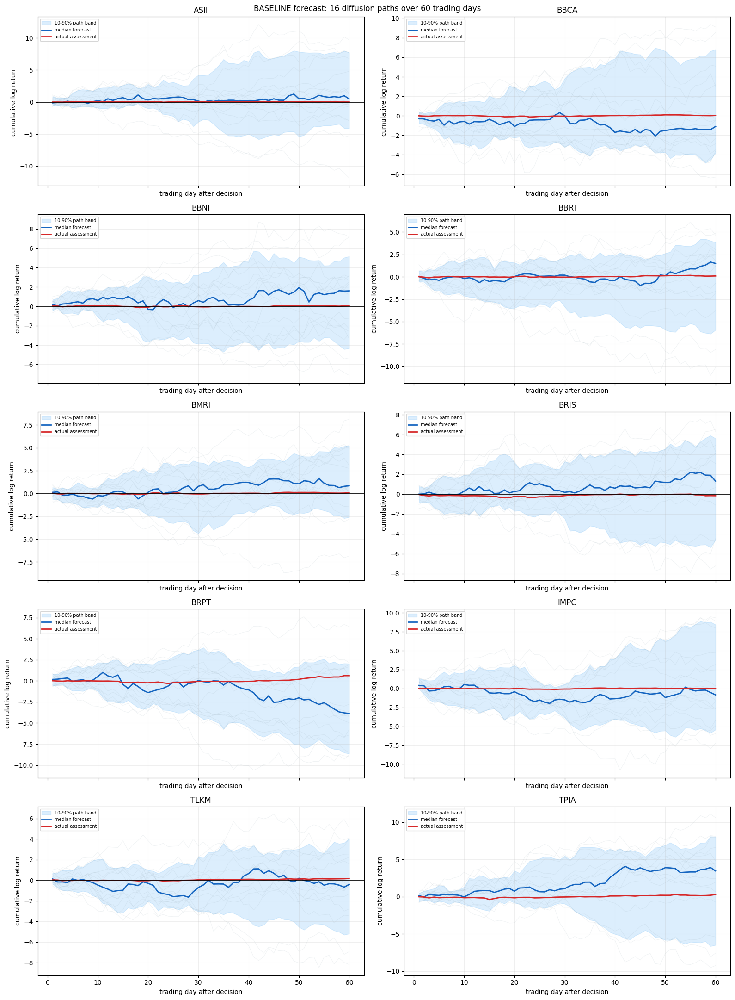

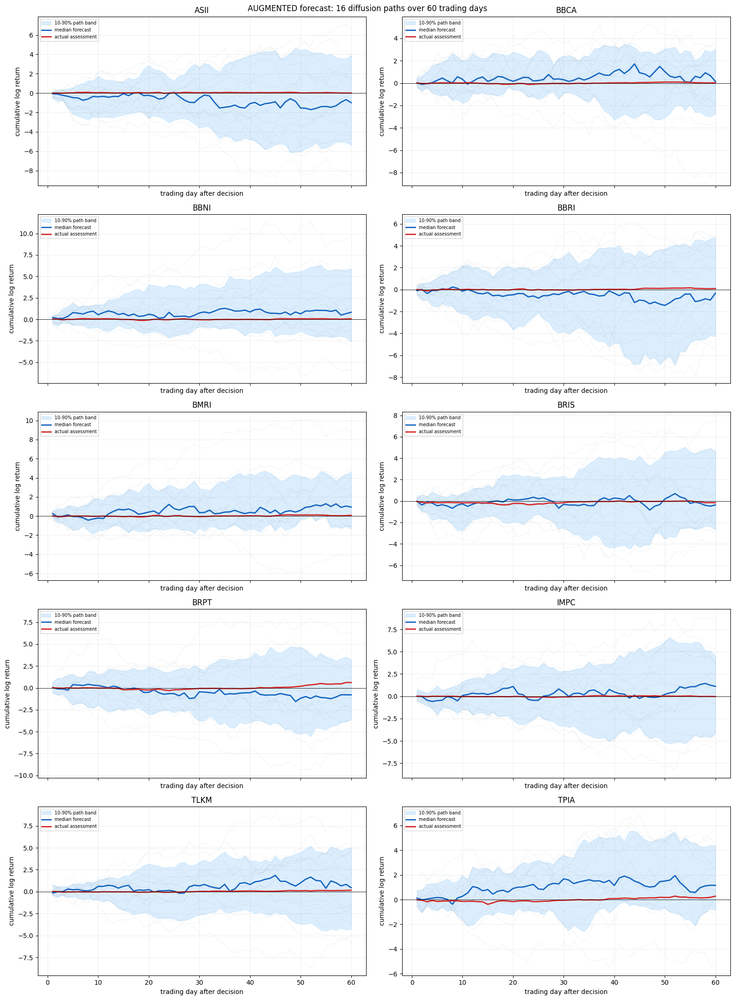

Yahoo close used as the zero point for frozen-cutoff actual comparison:


,ticker,cutoff_date,yahoo_cutoff_date,yahoo_cutoff_close
0,ASII,2026-07-01,2026-07-01,4600.0
1,BBCA,2026-07-01,2026-07-01,5600.0
2,BBNI,2026-07-01,2026-07-01,3100.0
3,BBRI,2026-07-01,2026-07-01,2670.0
4,BMRI,2026-07-01,2026-07-01,3810.0
5,BRIS,2026-07-01,2026-07-01,1665.0
6,BRPT,2026-07-01,2026-07-01,1380.0
7,IMPC,2026-07-01,2026-07-01,1390.0
8,TLKM,2026-07-01,2026-07-01,2440.0
9,TPIA,2026-07-01,2026-07-01,1680.0


Frozen cutoff forecast visual: paths start at 2026-07-01; actual Yahoo leg is partial_horizon when fewer than 60 trading days are available.


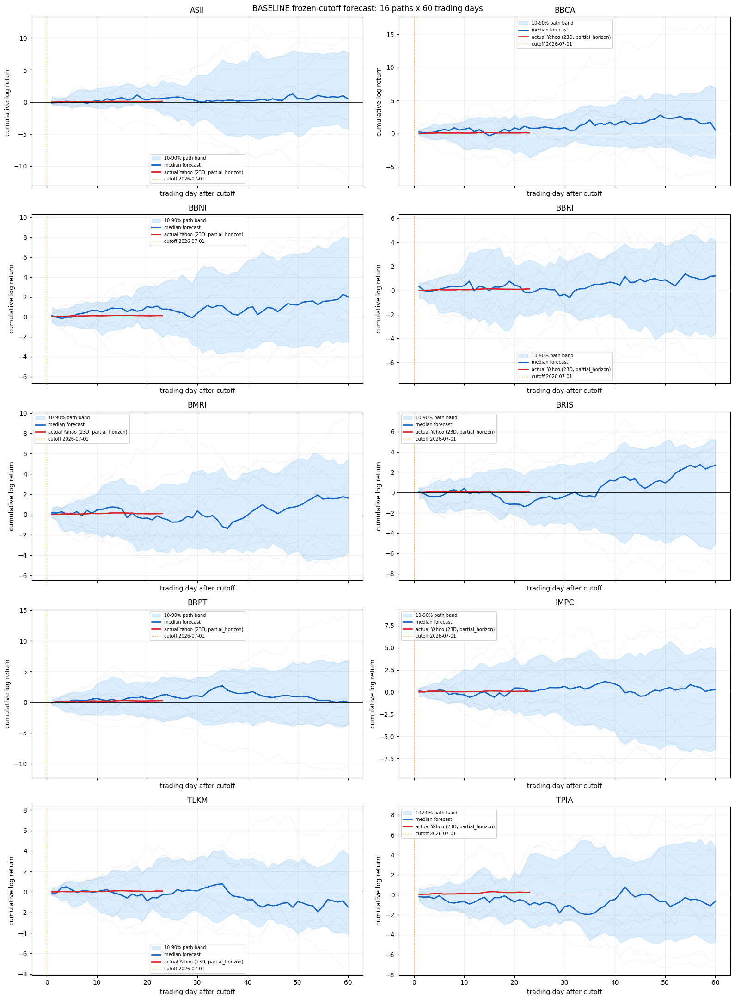

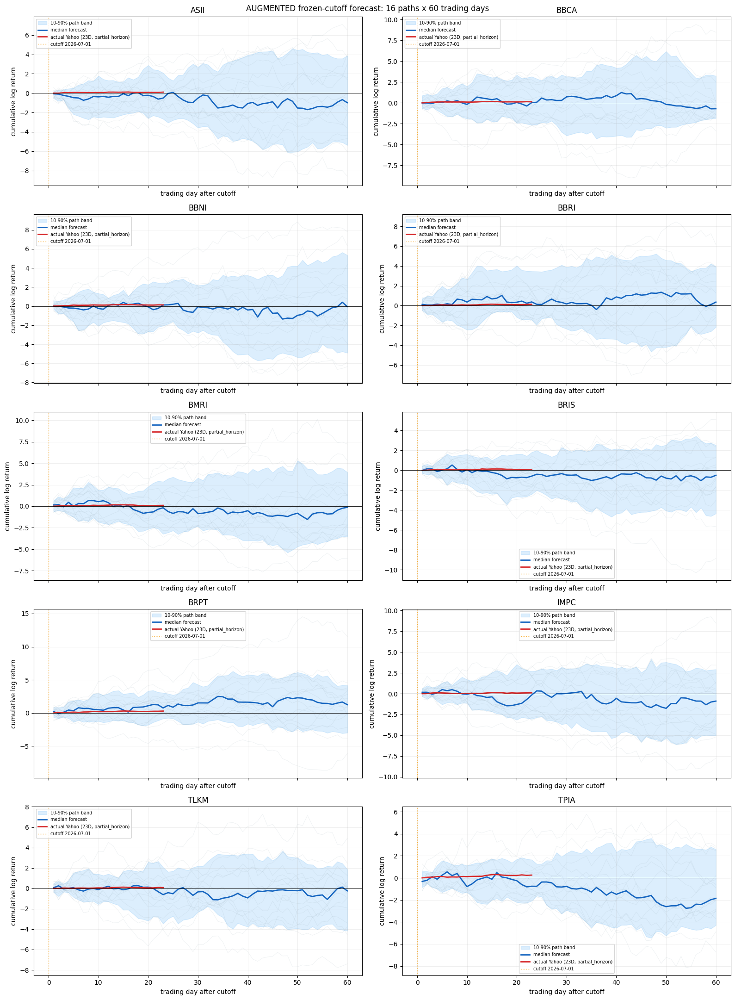

In [34]:
print('Forecast visual check: each emitter uses 16 stochastic diffusion paths over a 60-trading-day horizon.')
for variant,all_paths,meta in [('baseline',base_paths,base_meta),('augmented',aug_paths,aug_meta)]:
    fig,axes=plt.subplots(5,2,figsize=(16,22),sharex=True)
    for ax,ticker in zip(axes.flat,TICKERS):
        idx=np.flatnonzero(meta.ticker.eq(ticker).to_numpy() & assessment_mask)
        if not len(idx): ax.set_title(ticker+' no assessment window'); continue
        local=np.where(assessment_idx==idx[0])[0][0]; paths=all_paths[local]; truth=actual[local]; xday=np.arange(1,H+1); cumulative=np.cumsum(paths,axis=1); truth_cumulative=np.cumsum(truth)
        for path in cumulative: ax.plot(xday,path,alpha=.13,color='#90a4ae',linewidth=.8)
        ax.fill_between(xday,np.quantile(cumulative,.10,axis=0),np.quantile(cumulative,.90,axis=0),color='#64b5f6',alpha=.22,label='10-90% path band')
        ax.plot(xday,np.median(cumulative,axis=0),color='#1565c0',linewidth=2,label='median forecast')
        ax.plot(xday,truth_cumulative,color='#d62728',linewidth=2,label='actual assessment')
        ax.axhline(0,color='black',linewidth=.6); ax.set_title(ticker); ax.set_xlabel('trading day after decision'); ax.set_ylabel('cumulative log return'); ax.grid(alpha=.2); ax.legend(fontsize=7)
    plt.suptitle(f'{variant.upper()} forecast: 16 diffusion paths over 60 trading days'); plt.tight_layout(); plt.show()
# Build this comparison before plotting the frozen-cutoff paths. The paper-replay cell later
# recomputes the same table, but forecast visualization must be independently executable.
cutoff_ts=pd.Timestamp(cutoff)
cutoff_price_rows=[]
for ticker in TICKERS:
    history=yahoo_raw[(yahoo_raw.ticker.eq(ticker))&(yahoo_raw.date<=cutoff_ts)].sort_values('date')
    row=history.iloc[-1] if len(history) else None
    cutoff_price_rows.append({'ticker':ticker,'cutoff_date':cutoff_ts.date(),'yahoo_cutoff_date':row.date.date() if row is not None else pd.NaT,'yahoo_cutoff_close':float(row.close) if row is not None else np.nan})
cutoff_price_comparison=pd.DataFrame(cutoff_price_rows)
print('Yahoo close used as the zero point for frozen-cutoff actual comparison:')
display(cutoff_price_comparison.round(6))
print('Frozen cutoff forecast visual: paths start at 2026-07-01; actual Yahoo leg is partial_horizon when fewer than 60 trading days are available.')
for variant,all_paths in [('baseline',cutoff_base_paths),('augmented',cutoff_aug_paths)]:
    fig,axes=plt.subplots(5,2,figsize=(16,22),sharex=True)
    for ax,ticker in zip(axes.flat,TICKERS):
        local=np.flatnonzero(cutoff_meta.ticker.eq(ticker).to_numpy())[0]; paths=all_paths[local]; cumulative=np.cumsum(paths,axis=1); xday=np.arange(1,H+1)
        s=yahoo_raw[(yahoo_raw.ticker.eq(ticker))&(yahoo_raw.date>=cutoff)].sort_values('date'); start=cutoff_price_comparison[cutoff_price_comparison.ticker.eq(ticker)].iloc[0].yahoo_cutoff_close
        actual_prices=np.concatenate([[start],s.close.to_numpy(dtype=float)]); actual_cumulative=np.cumsum(np.diff(np.log(actual_prices))) if len(actual_prices)>1 else np.array([]); actual_days=np.arange(1,len(actual_cumulative)+1)
        for path in cumulative: ax.plot(xday,path,alpha=.13,color='#90a4ae',linewidth=.8)
        ax.fill_between(xday,np.quantile(cumulative,.10,axis=0),np.quantile(cumulative,.90,axis=0),color='#64b5f6',alpha=.22,label='10-90% path band')
        ax.plot(xday,np.median(cumulative,axis=0),color='#1565c0',linewidth=2,label='median forecast')
        if len(actual_cumulative): ax.plot(actual_days,actual_cumulative,color='#d62728',linewidth=2,label=f'actual Yahoo ({len(actual_cumulative)}D, partial_horizon)')
        ax.axvline(0,color='#f9a825',linestyle=':',linewidth=1,label='cutoff 2026-07-01'); ax.axhline(0,color='black',linewidth=.6); ax.set_title(ticker); ax.set_xlabel('trading day after cutoff'); ax.set_ylabel('cumulative log return'); ax.grid(alpha=.2); ax.legend(fontsize=7)
    plt.suptitle(f'{variant.upper()} frozen-cutoff forecast: 16 paths x 60 trading days'); plt.tight_layout(); plt.show()


### Penjelasan output

Grafik forecast memperlihatkan seluruh path, median, rentang 10-90 persen, dan actual assessment bila tersedia. Garis atau marker cutoff memisahkan kondisi yang diketahui model dari target masa depan. Visual ini dipakai untuk memeriksa bentuk distribusi dan kecocokan actual, bukan sebagai pengganti metrik numerik.


## 16. External Post-Cutoff Data dan Paper Replay Terpisah
### 16.1 Actual leg setelah cutoff
### 16.2 Paper replay ledger
### 16.3 Portfolio summary

Bagian ini memakai data Yahoo Finance setelah cutoff hanya sebagai actual comparison dan paper-trading replay. Replay menggunakan signal augmented frozen cutoff, entry next valid EOD, alokasi virtual, stop-loss 3 persen, close count, exit reason, dan kurva portfolio terpisah dari training.


Attached Yahoo dataset range: 2020-01-02 to 2026-07-31
Paper replay uses attached CSV through: 2026-07-31


,ticker,first_date,last_date,rows,close_start,close_end
0,ASII,2026-07-02,2026-07-31,22,4580.0,5100.0
1,BBCA,2026-07-02,2026-07-31,22,5800.0,6325.0
2,BBNI,2026-07-02,2026-07-31,22,3170.0,3530.0
3,BBRI,2026-07-02,2026-07-31,22,2690.0,3040.0
4,BMRI,2026-07-02,2026-07-31,22,3900.0,4190.0
5,BRIS,2026-07-02,2026-07-31,22,1690.0,1820.0
6,BRPT,2026-07-02,2026-07-31,22,1500.0,1845.0
7,IMPC,2026-07-02,2026-07-31,22,1415.0,1545.0
8,TLKM,2026-07-02,2026-07-31,22,2450.0,2630.0
9,TPIA,2026-07-02,2026-07-31,22,1770.0,2160.0


Yahoo actual close at cutoff and next valid EOD entry: same source, separated by time.


,ticker,cutoff_date,yahoo_cutoff_date,yahoo_cutoff_close,next_eod_date,next_eod_close
0,ASII,2026-07-01,2026-07-01,4600.0,2026-07-02,4580.0
1,BBCA,2026-07-01,2026-07-01,5600.0,2026-07-02,5800.0
2,BBNI,2026-07-01,2026-07-01,3100.0,2026-07-02,3170.0
3,BBRI,2026-07-01,2026-07-01,2670.0,2026-07-02,2690.0
4,BMRI,2026-07-01,2026-07-01,3810.0,2026-07-02,3900.0
5,BRIS,2026-07-01,2026-07-01,1665.0,2026-07-02,1690.0
6,BRPT,2026-07-01,2026-07-01,1380.0,2026-07-02,1500.0
7,IMPC,2026-07-01,2026-07-01,1390.0,2026-07-02,1415.0
8,TLKM,2026-07-01,2026-07-01,2440.0,2026-07-02,2450.0
9,TPIA,2026-07-01,2026-07-01,1680.0,2026-07-02,1770.0


{'initial_capital': 100000000.0, 'target_allocation_per_ticker': 5000000.0, 'policy_reserve_cash': 50000000.0, 'stop_loss': 0.03, 'cooldown_days': 5, 'same_day_reentry': False}
Paper replay uses the augmented frozen cutoff signal once; it does not re-infer a new signal each day.
Execution semantics: initial position_state=Flat; only execution_action=Buy opens a position; Hold means Keep only when a Long position already exists.
Paper replay ledger: one cutoff decision, next valid EOD entry, fixed 3% stop, no same-day re-entry.


,ticker,signal_at_cutoff,model_signal,position_state_at_decision,execution_action,close_count,position_closed,entry_date,entry_price,exit_date,exit_price,exit_reason,allocated_capital,gross_return,pnl,cash_after_exit,cooldown_days,reentry_allowed,capital_after_trade
0,ASII,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
1,BBCA,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
2,BBNI,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
3,BBRI,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
4,BMRI,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
5,BRIS,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
6,BRPT,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
7,IMPC,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
8,TLKM,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0
9,TPIA,Hold,Hold,Flat,No Entry,0,False,NaT,NaN,NaT,NaN,no_buy_signal_at_cutoff,0.0,0.0,0.0,100000000.0,5,False,100000000.0


,initial_capital,policy_reserve_cash,allocated_capital,ending_capital,total_pnl,total_return,trades_entered,closed_positions,close_events,stop_loss_exits,snapshot_end_exits,reentry_events
0,100000000.0,50000000.0,0.0,100000000.0,0.0,0.0,0,0,0,0,0,0


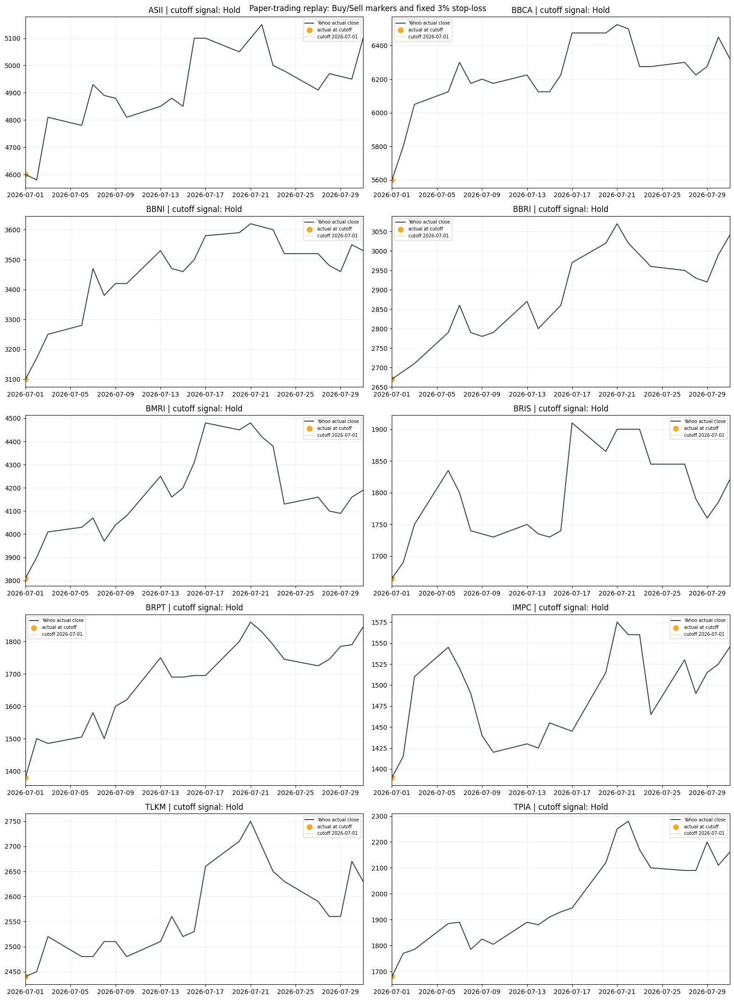

Portfolio curve uses one account-level equity value, not an average of ticker-level values.


,date,portfolio_value,cumulative_pnl
0,2026-07-02,100000000.0,0.0
1,2026-07-03,100000000.0,0.0
2,2026-07-06,100000000.0,0.0
3,2026-07-07,100000000.0,0.0
4,2026-07-08,100000000.0,0.0
5,2026-07-09,100000000.0,0.0
6,2026-07-10,100000000.0,0.0
7,2026-07-13,100000000.0,0.0
8,2026-07-14,100000000.0,0.0
9,2026-07-15,100000000.0,0.0


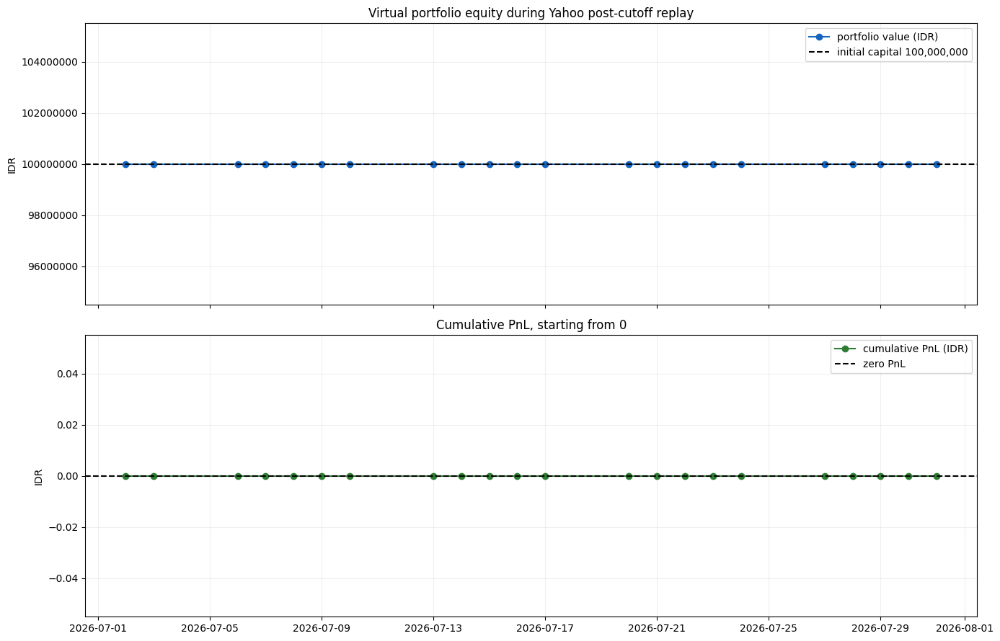

This isolated paper replay is not mixed into Yahoo-core training features and is not used for tuning.


In [35]:
yf_cutoff=pd.Timestamp('2026-07-01'); yf_end=yahoo_raw.date.max()
latest=yahoo_raw[(yahoo_raw.date>yf_cutoff)&(yahoo_raw.date<=yf_end)].copy().sort_values(['ticker','date'])
print('Attached Yahoo dataset range:',yahoo_raw.date.min().date(),'to',yahoo_raw.date.max().date())
print('Paper replay uses attached CSV through:',yf_end.date())
latest_summary=latest.groupby('ticker').agg(first_date=('date','min'),last_date=('date','max'),rows=('date','size'),close_start=('close','first'),close_end=('close','last')).reset_index()
display(latest_summary)

def last_on_or_before(frame, date):
    s=frame[frame.date<=date].sort_values('date')
    return s.iloc[-1] if len(s) else None
cutoff_price_rows=[]
for ticker in TICKERS:
    y=last_on_or_before(yahoo_raw[yahoo_raw.ticker.eq(ticker)],yf_cutoff)
    post=latest[latest.ticker.eq(ticker)].sort_values('date'); entry=post.iloc[0] if len(post) else None
    y_close=float(y.close) if y is not None else np.nan
    cutoff_price_rows.append({'ticker':ticker,'cutoff_date':yf_cutoff.date(),'yahoo_cutoff_date':y.date.date() if y is not None else pd.NaT,'yahoo_cutoff_close':y_close,'next_eod_date':entry.date.date() if entry is not None else pd.NaT,'next_eod_close':float(entry.close) if entry is not None else np.nan})
cutoff_price_comparison=pd.DataFrame(cutoff_price_rows)
print('Yahoo actual close at cutoff and next valid EOD entry: same source, separated by time.')
display(cutoff_price_comparison.round(6))

INITIAL_CAPITAL=100_000_000.0; TARGET_ALLOCATION=5_000_000.0; POLICY_RESERVE=50_000_000.0; STOP_LOSS=0.03; COOLDOWN_DAYS=5
print({'initial_capital':INITIAL_CAPITAL,'target_allocation_per_ticker':TARGET_ALLOCATION,'policy_reserve_cash':POLICY_RESERVE,'stop_loss':STOP_LOSS,'cooldown_days':COOLDOWN_DAYS,'same_day_reentry':False})
print('Paper replay uses the augmented frozen cutoff signal once; it does not re-infer a new signal each day.')
print('Execution semantics: initial position_state=Flat; only execution_action=Buy opens a position; Hold means Keep only when a Long position already exists.')
cutoff_aug_signal=cutoff_decision[cutoff_decision.variant.eq('augmented')].set_index('ticker')
trade_rows=[]; daily_rows=[]; position_rows=[]
for ticker in TICKERS:
    s=latest[latest.ticker.eq(ticker)].sort_values('date').reset_index(drop=True); signal=cutoff_aug_signal.loc[ticker,'model_signal'] if ticker in cutoff_aug_signal.index else 'Hold'; position_state='Flat'; execution_action=resolve_execution_action(signal,position_state)
    cash=INITIAL_CAPITAL; qty=0.0; entry_price=np.nan; stop_price=np.nan; entry_date=None; exit_date=None; exit_price=np.nan; exit_reason='no_buy_signal_at_cutoff'
    if execution_action=='Buy' and len(s):
        entry_date=s.loc[0,'date']; entry_price=float(s.loc[0,'close']); stop_price=entry_price*(1-STOP_LOSS); qty=TARGET_ALLOCATION/entry_price; cash-=TARGET_ALLOCATION
        for j in range(1,len(s)):
            if float(s.loc[j,'close'])<=stop_price:
                exit_date=s.loc[j,'date']; exit_price=float(s.loc[j,'close']); exit_reason='fixed_stop_loss_3pct'; break
        if exit_date is None:
            exit_date=s.loc[len(s)-1,'date']; exit_price=float(s.loc[len(s)-1,'close']); exit_reason='end_of_attached_snapshot'
        cash+=qty*exit_price; position_rows.append({'ticker':ticker,'entry_date':entry_date,'entry_price':entry_price,'stop_price':stop_price,'exit_date':exit_date,'exit_price':exit_price,'exit_reason':exit_reason,'quantity':qty})
        trade_rows.append({'ticker':ticker,'signal_at_cutoff':signal,'model_signal':signal,'position_state_at_decision':position_state,'execution_action':execution_action,'close_count':int(exit_date is not None),'position_closed':bool(exit_date is not None),'entry_date':entry_date,'entry_price':entry_price,'exit_date':exit_date,'exit_price':exit_price,'exit_reason':exit_reason,'allocated_capital':TARGET_ALLOCATION,'gross_return':exit_price/entry_price-1,'pnl':qty*(exit_price-entry_price),'cash_after_exit':cash,'cooldown_days':COOLDOWN_DAYS,'reentry_allowed':False})
    else:
        trade_rows.append({'ticker':ticker,'signal_at_cutoff':signal,'model_signal':signal,'position_state_at_decision':position_state,'execution_action':execution_action,'close_count':0,'position_closed':False,'entry_date':pd.NaT,'entry_price':np.nan,'exit_date':pd.NaT,'exit_price':np.nan,'exit_reason':'no_buy_signal_at_cutoff','allocated_capital':0.0,'gross_return':0.0,'pnl':0.0,'cash_after_exit':INITIAL_CAPITAL,'cooldown_days':COOLDOWN_DAYS,'reentry_allowed':False})
    for _,bar in s.iterrows():
        marked_cash=INITIAL_CAPITAL-sum(t['allocated_capital'] for t in trade_rows if t['ticker']!=ticker and t['entry_date'] is not None)
        marked_value=marked_cash
        for t in position_rows:
            if t['ticker']==ticker and pd.notna(t['entry_date']) and bar.date>=t['entry_date'] and bar.date<=t['exit_date']: marked_value+=t['quantity']*float(bar.close)
        daily_rows.append({'date':bar.date,'ticker':ticker,'signal_at_cutoff':signal,'portfolio_value_marked':marked_value})
replay_df=pd.DataFrame(trade_rows); position_df=pd.DataFrame(position_rows); daily_df=pd.DataFrame(daily_rows)
replay_df['capital_after_trade']=INITIAL_CAPITAL+replay_df.pnl.cumsum()
print('Paper replay ledger: one cutoff decision, next valid EOD entry, fixed 3% stop, no same-day re-entry.')
display(replay_df.round(6))
portfolio_summary=pd.DataFrame([{'initial_capital':INITIAL_CAPITAL,'policy_reserve_cash':POLICY_RESERVE,'allocated_capital':replay_df.allocated_capital.sum(),'ending_capital':INITIAL_CAPITAL+replay_df.pnl.sum(),'total_pnl':replay_df.pnl.sum(),'total_return':replay_df.pnl.sum()/INITIAL_CAPITAL,'trades_entered':int((replay_df.allocated_capital>0).sum()),'closed_positions':int(replay_df.position_closed.sum()),'close_events':int(replay_df.close_count.sum()),'stop_loss_exits':int((replay_df.exit_reason=='fixed_stop_loss_3pct').sum()),'snapshot_end_exits':int((replay_df.exit_reason=='end_of_attached_snapshot').sum()),'reentry_events':0}])
display(portfolio_summary.round(6))
fig,axes=plt.subplots(5,2,figsize=(16,22),sharex=False)
for ax,ticker in zip(axes.flat,TICKERS):
    s=latest[latest.ticker.eq(ticker)].sort_values('date'); cutoff_s=yahoo_raw[(yahoo_raw.ticker.eq(ticker))&(yahoo_raw.date<=yf_cutoff)].sort_values('date').tail(1); plot_s=pd.concat([cutoff_s,s],ignore_index=True).drop_duplicates('date').sort_values('date'); row=replay_df[replay_df.ticker.eq(ticker)].iloc[0]; ax.plot(plot_s.date,plot_s.close,color='#37474f',label='Yahoo actual close')
    cutoff_row=cutoff_price_comparison[cutoff_price_comparison.ticker.eq(ticker)].iloc[0]; ax.scatter([yf_cutoff],[cutoff_row.yahoo_cutoff_close],color='#f9a825',s=65,marker='o',label='actual at cutoff'); ax.axvline(yf_cutoff,color='#f9a825',linestyle=':',linewidth=1,label='cutoff 2026-07-01')
    if pd.notna(row.entry_date):
        ax.scatter([row.entry_date],[row.entry_price],color='#00c853',s=70,marker='^',label='BUY at next EOD'); ax.axhline(row.entry_price*(1-STOP_LOSS),color='#ff1744',linestyle='--',linewidth=1,label='stop loss -3%'); ax.scatter([row.exit_date],[row.exit_price],color='#d50000',s=70,marker='v',label='SELL / exit')
    if len(plot_s): ax.set_xlim(plot_s.date.min(),plot_s.date.max()); ax.margins(x=0)
    ax.set_title(f'{ticker} | cutoff signal: {row.signal_at_cutoff}'); ax.grid(alpha=.2); ax.legend(fontsize=7)
plt.suptitle('Paper-trading replay: Buy/Sell markers and fixed 3% stop-loss'); plt.tight_layout(); plt.show()
# Build one portfolio equity curve. Do not average separate per-ticker portfolio values.
all_dates=pd.DatetimeIndex(sorted(latest.date.unique())) if len(latest) else pd.DatetimeIndex([]); equity_rows=[]
for date in all_dates:
    equity=INITIAL_CAPITAL
    for pos in position_rows:
        if date < pos['entry_date']: continue
        price_row=latest[(latest.ticker.eq(pos['ticker']))&(latest.date.eq(date))]
        mark=float(price_row.iloc[0].close) if len(price_row) else float(pos['exit_price'])
        mark=min(mark,float(pos['exit_price'])) if date>pos['exit_date'] else mark
        equity += float(pos['quantity'])*(mark-float(pos['entry_price']))
    equity_rows.append({'date':date,'portfolio_value':equity,'cumulative_pnl':equity-INITIAL_CAPITAL})
daily_portfolio=pd.DataFrame(equity_rows)
if len(daily_portfolio):
    print('Portfolio curve uses one account-level equity value, not an average of ticker-level values.')
    display(daily_portfolio.round(2))
    fig,axes=plt.subplots(2,1,figsize=(14,9),sharex=True)
    axes[0].plot(daily_portfolio.date,daily_portfolio.portfolio_value,marker='o',color='#1565c0',label='portfolio value (IDR)'); axes[0].axhline(INITIAL_CAPITAL,color='black',linestyle='--',label='initial capital 100,000,000'); axes[0].set_title('Virtual portfolio equity during Yahoo post-cutoff replay'); axes[0].set_ylabel('IDR'); axes[0].ticklabel_format(axis='y',style='plain'); axes[0].grid(alpha=.2); axes[0].legend()
    axes[1].plot(daily_portfolio.date,daily_portfolio.cumulative_pnl,marker='o',color='#2e7d32',label='cumulative PnL (IDR)'); axes[1].axhline(0,color='black',linestyle='--',label='zero PnL'); axes[1].set_title('Cumulative PnL, starting from 0'); axes[1].set_ylabel('IDR'); axes[1].ticklabel_format(axis='y',style='plain'); axes[1].grid(alpha=.2); axes[1].legend()
    plt.tight_layout(); plt.show()
print('This isolated paper replay is not mixed into Yahoo-core training features and is not used for tuning.')

### Penjelasan output

Ledger paper replay memperlihatkan kapan posisi virtual masuk pada next valid EOD, kapan ditutup, alasan exit, close count, PnL, dan modal setelah trade. Replay memakai augmented frozen cutoff signal dan data Yahoo setelah cutoff, bukan retraining harian. Kurva portfolio dimulai dari modal IDR 100.000.000 dan menghitung satu nilai akun, bukan rata-rata antar emiten.


## 17. Fibonacci Interaction Diagnostics dan Visualisasi
### 17.1 Candidate chart set
### 17.2 Interaction event counts
### 17.3 Heatmap dan contact sheet

Bagian ini menghasilkan 48 chart kandidat, tabel interaction events, touch heatmap, dan contact sheet. Ini adalah diagnostik interaksi historis dan tidak otomatis menjadi fitur model atau probabilitas terkalibrasi.


Fibonacci diagnostics generated: 48 charts and 240 level-event rows


,parent_case_id,candidate_id,ticker,timeframe,scope,perspective,swing_low_date,swing_low_price,swing_high_date,swing_high_price,direction,level,level_price,touch_count,rejection_count,breakout_count,retest_count,liquidity_sweep_count,source
0,FIB00001,FIB00001_wide,ASII,1D,major_cycle,wide,2020-03-26,3220.0,2022-04-28,7700.0,up,0.382,5988.64,105,69,51,0,0,automatic diagnostic from Yahoo raw OHLCV
1,FIB00001,FIB00001_wide,ASII,1D,major_cycle,wide,2020-03-26,3220.0,2022-04-28,7700.0,up,0.500,5460.00,91,61,43,0,0,automatic diagnostic from Yahoo raw OHLCV
2,FIB00001,FIB00001_wide,ASII,1D,major_cycle,wide,2020-03-26,3220.0,2022-04-28,7700.0,up,0.618,4931.36,152,120,60,0,0,automatic diagnostic from Yahoo raw OHLCV
3,FIB00001,FIB00001_wide,ASII,1D,major_cycle,wide,2020-03-26,3220.0,2022-04-28,7700.0,up,1.000,3220.00,1,0,1,0,0,automatic diagnostic from Yahoo raw OHLCV
4,FIB00001,FIB00001_wide,ASII,1D,major_cycle,wide,2020-03-26,3220.0,2022-04-28,7700.0,up,1.618,451.36,0,0,1,0,0,automatic diagnostic from Yahoo raw OHLCV
5,FIB00001,FIB00001_medium,ASII,1D,major_cycle,medium,2026-06-08,4350.0,2026-01-19,7475.0,down,0.382,5543.75,17,14,10,0,0,automatic diagnostic from Yahoo raw OHLCV
6,FIB00001,FIB00001_medium,ASII,1D,major_cycle,medium,2026-06-08,4350.0,2026-01-19,7475.0,down,0.500,5912.50,35,23,14,0,0,automatic diagnostic from Yahoo raw OHLCV
7,FIB00001,FIB00001_medium,ASII,1D,major_cycle,medium,2026-06-08,4350.0,2026-01-19,7475.0,down,0.618,6281.25,41,25,19,0,0,automatic diagnostic from Yahoo raw OHLCV
8,FIB00001,FIB00001_medium,ASII,1D,major_cycle,medium,2026-06-08,4350.0,2026-01-19,7475.0,down,1.000,7475.00,1,1,1,0,0,automatic diagnostic from Yahoo raw OHLCV
9,FIB00001,FIB00001_medium,ASII,1D,major_cycle,medium,2026-06-08,4350.0,2026-01-19,7475.0,down,1.618,9406.25,0,0,1,0,0,automatic diagnostic from Yahoo raw OHLCV


level,0.382,0.500,0.618,1.000,1.618
ticker,,,,,
ASII,250,258,416,6,0
BBCA,262,188,176,8,0
BBNI,450,240,120,8,0
BBRI,192,300,260,14,0
BMRI,132,284,234,18,0
BRIS,210,168,212,12,0
BRPT,44,42,61,3,0
IMPC,60,80,64,7,0
TLKM,203,153,141,3,0


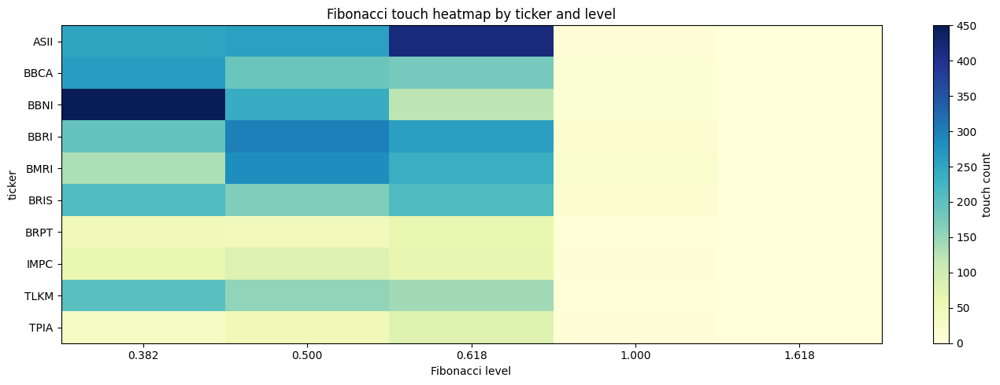

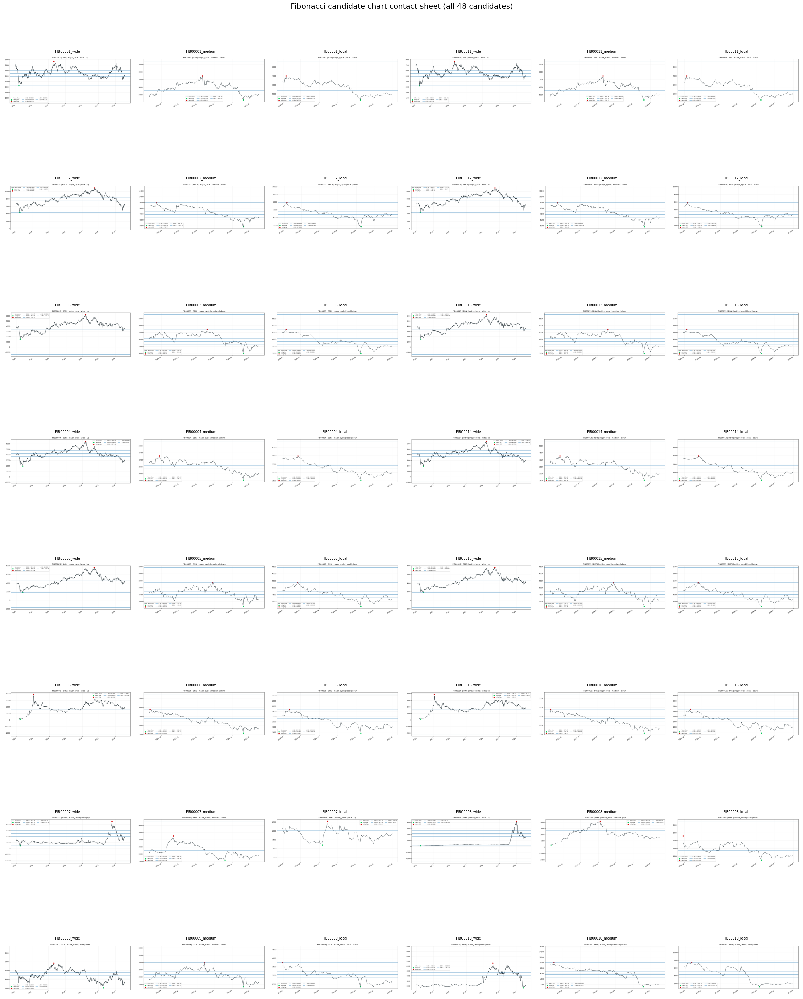

All chart files: /kaggle/working/raw_ohlcv_full_run/fibonacci_diagnostics/candidate_charts | summary: /kaggle/working/raw_ohlcv_full_run/fibonacci_diagnostics/fibonacci_interaction_summary.csv


In [36]:
fib_out=OUTPUT_ROOT/'fibonacci_diagnostics'; chart_out=fib_out/'candidate_charts'; chart_out.mkdir(parents=True,exist_ok=True)
case_specs=[]
for i,ticker in enumerate(TICKERS):
    case_specs.append((f'FIB{i+1:05d}',ticker,'major_cycle' if i<6 else ('active_trend' if i<12 else 'local_structure'),'1D'))
    if i<6: case_specs.append((f'FIB{i+11:05d}',ticker,'active_trend' if i%2==0 else 'major_cycle','1D'))
case_specs=case_specs[:16]
perspectives=[('wide',None),('medium',252),('local',120)]
levels=(.382,.5,.618,1.0,1.618); event_rows=[]; chart_paths=[]
def fib_candidate(group,window):
    view=group.tail(window).copy() if window else group.copy(); lo_i=view.low.idxmin(); hi_i=view.high.idxmax(); lo=float(view.loc[lo_i,'low']); hi=float(view.loc[hi_i,'high']); low_date=view.loc[lo_i,'date']; high_date=view.loc[hi_i,'date']; up=lo_i<hi_i; span=hi-lo
    fib={r:(hi-r*span if up else lo+r*span) for r in levels}; return view,lo,hi,low_date,high_date,up,fib

for case_id,ticker,scope,timeframe in case_specs:
    group=yahoo_raw[yahoo_raw.ticker.eq(ticker)].sort_values('date').copy()
    for perspective,window in perspectives:
        view,lo,hi,low_date,high_date,up,fib=fib_candidate(group,window)
        tol=.005
        for ratio,level in fib.items():
            touched=((view.low<=level*(1+tol))&(view.high>=level*(1-tol)))
            close_above=view.close>level*(1+tol); close_below=view.close<level*(1-tol)
            breakout=int((close_above & (~close_above.shift(1,fill_value=False))).sum()+(close_below & (~close_below.shift(1,fill_value=False))).sum())
            rejection=int((touched & ((view.close-level).abs()/level<.015)).sum())
            event_rows.append({'parent_case_id':case_id,'candidate_id':f'{case_id}_{perspective}','ticker':ticker,'timeframe':timeframe,'scope':scope,'perspective':perspective,'swing_low_date':str(low_date.date()),'swing_low_price':lo,'swing_high_date':str(high_date.date()),'swing_high_price':hi,'direction':'up' if up else 'down','level':ratio,'level_price':level,'touch_count':int(touched.sum()),'rejection_count':rejection,'breakout_count':breakout,'retest_count':0,'liquidity_sweep_count':0,'source':'automatic diagnostic from Yahoo raw OHLCV'})
        fig,ax=plt.subplots(figsize=(12,5)); ax.plot(view.date,view.close,color='#263238',linewidth=1.2,label='Yahoo close'); ax.scatter([low_date],[lo],color='#00c853',s=55,label='swing low'); ax.scatter([high_date],[hi],color='#d50000',s=55,label='swing high')
        for ratio,level in fib.items(): ax.axhline(level,linewidth=1,label=f'{ratio:.3f} = {level:.2f}')
        ax.set_title(f'{case_id} | {ticker} | {scope} | {perspective} | {'up' if up else 'down'}'); ax.grid(alpha=.2); ax.legend(fontsize=7,ncol=3); fig.autofmt_xdate(); plt.tight_layout()
        path=chart_out/f'{case_id}_{perspective}.png'; fig.savefig(path,dpi=120); chart_paths.append(path); plt.close(fig)
fib_events=pd.DataFrame(event_rows); fib_events.to_csv(fib_out/'fibonacci_interaction_summary.csv',index=False)
assert len(chart_paths)==48, f'Expected 48 Fibonacci charts, found {len(chart_paths)}'
print('Fibonacci diagnostics generated:',len(chart_paths),'charts and',len(fib_events),'level-event rows')
display(fib_events.head(15).round(4))
heat=fib_events.pivot_table(index='ticker',columns='level',values='touch_count',aggfunc='sum',fill_value=0).reindex(TICKERS)
display(heat.round(2))
fig,ax=plt.subplots(figsize=(14,5)); im=ax.imshow(heat.to_numpy(),aspect='auto',cmap='YlGnBu'); ax.set_xticks(range(len(heat.columns)),[f'{x:.3f}' for x in heat.columns]); ax.set_yticks(range(len(heat.index)),heat.index); ax.set_xlabel('Fibonacci level'); ax.set_ylabel('ticker'); ax.set_title('Fibonacci touch heatmap by ticker and level'); fig.colorbar(im,ax=ax,label='touch count'); plt.tight_layout(); plt.show()
chosen=chart_paths; fig,axes=plt.subplots(8,6,figsize=(24,32));
for ax,path in zip(axes.flat,chosen): ax.imshow(plt.imread(path)); ax.set_title(path.stem,fontsize=7); ax.axis('off')
plt.suptitle('Fibonacci candidate chart contact sheet (all 48 candidates)',fontsize=16); plt.tight_layout(); plt.show()
print('All chart files:',chart_out,'| summary:',fib_out/'fibonacci_interaction_summary.csv')


### Penjelasan output

Diagnostik Fibonacci menampilkan 48 chart kandidat, event touch/rejection/breakout/retest, heatmap level, dan contact sheet. Output ini menjawab bagaimana harga historis berinteraksi dengan level Fibonacci. Ia bersifat diagnostik dan tidak boleh dibaca sebagai probabilitas terkalibrasi atau label ex-post untuk training.


## 18. Output Inventory dan Reproducibility Summary
### 18.1 Output inventory
### 18.2 Reproducibility guards

Bagian ini mencatat file keluaran, ukuran, konfigurasi, dan guard status agar hasil dapat diaudit. Inventory bukan pengganti tabel atau visual output dari section sebelumnya.


In [37]:
inventory=[]
for path in sorted(OUTPUT_ROOT.rglob('*')):
    if path.is_file(): inventory.append({'file':str(path.relative_to(OUTPUT_ROOT)),'bytes':path.stat().st_size})
display(pd.DataFrame(inventory))
print('Training was performed in this notebook from raw OHLCV. No prior model output was used as training input.')

,file,bytes
0,fibonacci_diagnostics/candidate_charts/FIB0000...,66258
1,fibonacci_diagnostics/candidate_charts/FIB0000...,76020
2,fibonacci_diagnostics/candidate_charts/FIB0000...,93529
3,fibonacci_diagnostics/candidate_charts/FIB0000...,68043
4,fibonacci_diagnostics/candidate_charts/FIB0000...,74142
5,fibonacci_diagnostics/candidate_charts/FIB0000...,81652
6,fibonacci_diagnostics/candidate_charts/FIB0000...,68288
7,fibonacci_diagnostics/candidate_charts/FIB0000...,78775
8,fibonacci_diagnostics/candidate_charts/FIB0000...,84139
9,fibonacci_diagnostics/candidate_charts/FIB0000...,67140


Training was performed in this notebook from raw OHLCV. No prior model output was used as training input.


### Penjelasan output

Inventory mencatat file, ukuran, dan status guard dari fresh run. Bagian ini membantu memastikan checkpoint, metrics, forecast, decision matrix, paper replay, dan chart benar-benar tersimpan. Inventory hanya bukti keberadaan artefak; isi dan kualitasnya tetap harus dibaca dari tabel serta visual section terkait.


## 19. Research Summary dan Interpretasi Hasil
### 19.1 Baseline versus augmented
### 19.2 Interpretasi paper replay
### 19.3 Batasan dan scope final project

Section ini merangkum perbandingan baseline dan augmented setelah seluruh eksperimen selesai. CRPS menjadi metrik utama probabilistic forecast: nilai lebih rendah berarti distribusi forecast lebih dekat dengan actual assessment. Energy score, MAE, MSE, dan RMSE juga dibaca sebagai error, sehingga lebih rendah lebih baik. Coverage dibaca terhadap target interval, sedangkan sharpness dibaca bersama coverage dan tidak boleh dinilai sendirian.

Jalur yang dipilih sebagai hasil pengembangan harus ditentukan dari evidence numerik yang konsisten, bukan dari satu visual atau satu metrik. Paper replay menggunakan signal augmented frozen cutoff pada data Yahoo Finance post-cutoff dan dipisahkan dari training. Output replay mencatat modal awal, alokasi, PnL, return, jumlah posisi masuk, jumlah posisi tertutup, close event, stop-loss, exit snapshot, dan re-entry.

Fungsi final-project ini adalah menguji pipeline conditional diffusion untuk menghasilkan distribusi future-return path 60 trading days, membandingkan baseline dengan fitur Fibonacci timestamp-safe, memetakan distribusi ke decision head Buy/Hold/Sell, dan memperlihatkan evaluasi numerik serta replay yang dapat diaudit. Notebook ini bukan sistem live dan tidak melakukan retraining harian atau koneksi broker.

=== FORECAST MODEL COMPARISON ===


,variant,mean_crps,mean_energy_score,coverage_80,sharpness_80,mean_pit_rank,MAE,MSE,RMSE
0,baseline,0.131731,1.270688,0.998415,1.100251,0.499208,0.102762,0.017091,0.130733
1,augmented,0.137397,1.322417,0.998534,1.151387,0.502691,0.105690,0.017985,0.134107


Primary criterion: lower mean CRPS is better. Current CRPS winner: baseline.
mean_energy_score winner (lower is better): baseline
MAE winner (lower is better): baseline
MSE winner (lower is better): baseline
RMSE winner (lower is better): baseline
Interpretation: use the CRPS winner only when the other metrics and coverage do not show a material contradiction.


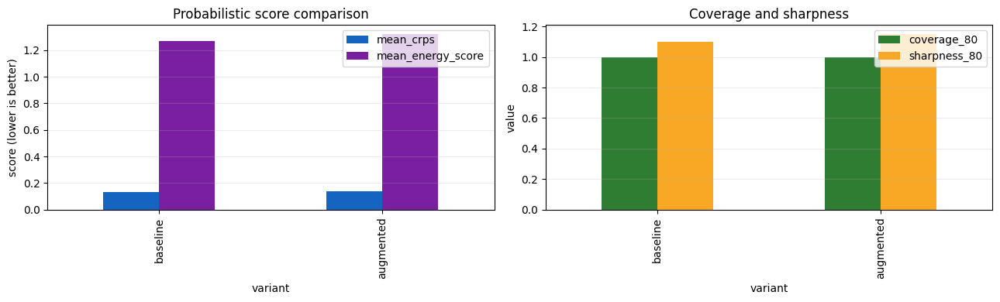

=== PAPER-TRADING REPLAY SUMMARY ===


,initial_capital,policy_reserve_cash,allocated_capital,ending_capital,total_pnl,total_return,trades_entered,closed_positions,close_events,stop_loss_exits,snapshot_end_exits,reentry_events
0,100000000.0,50000000.0,0.0,100000000.0,0.0,0.0,0,0,0,0,0,0


,metric,value
0,trades_entered,0
1,closed_positions,0
2,close_events,0
3,stop_loss_exits,0
4,snapshot_end_exits,0
5,profitable_closed_positions,0
6,loss_making_closed_positions,0


Paper replay source: augmented frozen cutoff signal; Yahoo Finance post-cutoff actual leg.
The replay is an isolated research diagnostic and is not mixed into model training or tuning.


In [38]:
print('=== FORECAST MODEL COMPARISON ===')
summary_metrics=metrics_df.reset_index().copy()
display(summary_metrics.round(6))
primary=summary_metrics.set_index('variant')['mean_crps']
winner=primary.idxmin()
print(f'Primary criterion: lower mean CRPS is better. Current CRPS winner: {winner}.')
for metric in ['mean_energy_score','MAE','MSE','RMSE']:
    if metric in summary_metrics.columns:
        ranked=summary_metrics.set_index('variant')[metric].sort_values()
        print(f'{metric} winner (lower is better): {ranked.index[0]}')
print('Interpretation: use the CRPS winner only when the other metrics and coverage do not show a material contradiction.')

fig,axes=plt.subplots(1,2,figsize=(13,4))
summary_metrics.plot(x='variant',y=['mean_crps','mean_energy_score'],kind='bar',ax=axes[0],color=['#1565c0','#7b1fa2'],title='Probabilistic score comparison')
axes[0].set_ylabel('score (lower is better)'); axes[0].grid(axis='y',alpha=.25); axes[0].legend()
summary_metrics.plot(x='variant',y=['coverage_80','sharpness_80'],kind='bar',ax=axes[1],color=['#2e7d32','#f9a825'],title='Coverage and sharpness')
axes[1].set_ylabel('value'); axes[1].grid(axis='y',alpha=.25); axes[1].legend()
plt.tight_layout(); plt.show()

print('=== PAPER-TRADING REPLAY SUMMARY ===')
display(portfolio_summary.round(6))
replay_counts=pd.DataFrame([{'metric':'trades_entered','value':int((replay_df.allocated_capital>0).sum())},{'metric':'closed_positions','value':int(replay_df.position_closed.sum())},{'metric':'close_events','value':int(replay_df.close_count.sum())},{'metric':'stop_loss_exits','value':int((replay_df.exit_reason=='fixed_stop_loss_3pct').sum())},{'metric':'snapshot_end_exits','value':int((replay_df.exit_reason=='end_of_attached_snapshot').sum())},{'metric':'profitable_closed_positions','value':int(((replay_df.position_closed)&(replay_df.pnl>0)).sum())},{'metric':'loss_making_closed_positions','value':int(((replay_df.position_closed)&(replay_df.pnl<0)).sum())}])
display(replay_counts)
print('Paper replay source: augmented frozen cutoff signal; Yahoo Finance post-cutoff actual leg.')
print('The replay is an isolated research diagnostic and is not mixed into model training or tuning.')


### Penjelasan output

Summary terakhir menggabungkan metrik baseline/augmented dan statistik paper replay. Baseline atau augmented dipilih berdasarkan CRPS yang lebih rendah sebagai kriteria utama, lalu diperiksa terhadap energy score dan coverage. PnL, jumlah posisi tertutup, stop-loss, profit, dan loss diambil dari `portfolio_summary` serta `replay_df`, sehingga tidak menggunakan angka contoh lama.
